# 07. Arm 3: MRAC design (A0) and a PRELIMINARY run

> **SUPERSEDED (2026-11-24): the PRELIMINARY run of sections 5.2-5.4, 6 and 8 used a no-load reference and is replaced by the arm-3 run with the nominal-payload reference in section 10.** The old run is kept below, unchanged, for the record; do not quote its numbers. (Its telemetry rows are the post-step rows of each tick, one tick later than the pre-step rows used by notebooks 06 and 08 and by section 10.)

**MRAC-RL logbook, step 3 of 3.** Arm 3 adds an adaptive inner loop that makes the *loaded* vehicle follow a **no-load reference model**. This notebook states the formulation (MQP §1.2, §4, §6), reports the feasibility gate for the chosen gains, and shows a **PRELIMINARY** run of the payload-aware law with the estimates ONLINE, FROZEN and FROZEN-after-learning, against PID+FF with mass-blind feedforward.

> **EXPLORATORY / offline / PROXY, and PRELIMINARY.** Arm 3 is design plus one short run per cell, three payload masses, one reference, gains chosen once by a stability scan (not by performance). Reduced taut point-load plant, development PC. **No claim of stability, convergence or benefit; no claim about the Pymunk chain plant.** Theory source: MQP (`.ai/research/derivations/mrac-quadrotor-payload.md`, status PROPOSED, not accepted). The double-integrator "Form 2" law of the formulation plan is **superseded** by the reviewed inertia-weighted B3 route (b) of MQP §4 and §6; it is not used here.

### Notation used across this series (added 2026-11-25)

The thesis notation (`thesis_book/residual.tex`, lines 95-292) is primary. The code and the derivation document (MQP) use their own symbols, mapped in the thesis file `.ai/research/derivations/notation-residual-tex.md`.

| This notebook / code | residual.tex | Note |
|---|---|---|
| `m_L`, `l` | $m_b$, $\ell$ | payload mass, rope length |
| `m_q`, `J`; `f`, `tau` | $m_q$, $J_q$; $f_q$, $\tau_q$ | |
| `phi` (code) | $\varphi$ | **$\varphi_{\rm tex} = -\varphi_{\rm code}$** with the cable at the vehicle CoG ($d = 0$). Odd functions of $\varphi$ flip sign; $\cos\varphi$, the tension and the tangent do not. With an offset $d\ne0$ the map is nonlinear |
| task reference `p_r(t)` | $x^d$ ("reference state" in residual.tex) | not Guha's reference model $x_r$ |

Numbers in this notebook are unchanged; only the reading of the symbols is aligned.

## 1. Research question

1. What exactly is the A0 architecture for arm 3, which uncertainty does it treat as matched and which not (MQP §1.3), and which derivation obligations are still open?
2. For the gains used here, is the pre-tuning feasibility gate $Q\succ0$ satisfied over a declared effectiveness family (MQP §6.7)?
3. In a short offline run with a payload the reference does not carry, what do the estimates do (ONLINE), and how does the loaded vehicle's tracking compare with PID+FF with a mass-blind feedforward and with the FROZEN twins?

## 2. Hypotheses and predicted direction

Stated before the run; the run is one deterministic episode per cell, so these are *directions*, not tests.

| # | Hypothesis | Predicted direction |
|---|---|---|
| H1 | The chosen gains pass the $Q$ gate over the declared family $\kappa,\kappa_\tau\in[0.9,1.1]$, and the original unit-test gains of `test_baselines.py` do not (the gate is a real constraint on $k_p,k_\theta,\lambda_\theta$) | margin $>0$ for the chosen gains; margin $<0$ for $k_p=40,k_\theta=5,\lambda_\theta=3$ |
| H2 | ONLINE payload estimates move away from their initial value 0 in the direction of the real payload mass (larger for 6 kg than for 2 kg) in the first seconds | $\hat m_L(t)>0$, ordered with $m_L$; **not** a claim of convergence to $m_L$ (the estimates are controller coefficients, MQP §6.3) |
| H3 | Under the payload mismatch ONLINE tracks the min-jerk reference at least as well as FROZEN (estimates fixed at their nominal values) | $c_{T,off}$(ONLINE) $\le c_{T,off}$(FROZEN) for the heavier masses |
| H4 | The law has no swing term, so it does **not** reduce swing relative to PID+FF | $c_{S,off}\gtrsim1$ for all arm-3 variants; this is why the softer law needs its own reference (section 4.5) |

## 3. Experiment identity

In [1]:
%matplotlib inline
import dataclasses, math, time
from functools import lru_cache

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from mrac_lab import provenance, style, plots, widgets

prov = provenance.setup(pinned_commit="2a329ad")
style.init()

from experiments.mrac.baselines import (
    canonical_offline_params, run_episode, MinJerkReference, PIDReferenceModel, EpisodeFailure,
    swing_equilibrium_off, S30_MASSES,
)
from experiments.mrac.offline_metrics import episode_metrics, c_T_off, c_S_off
from experiments.mrac.payload_law import (
    ClosedLoop, LoopState, PayloadLaw, PayloadLawParams, q_gate, q_gate_family, f_max_from_t_max,
)
from experiments.mrac.quad import QuadState

CANON = canonical_offline_params()
VEH, G = CANON.quad, CANON.quad.g
SOURCES = {r.name + " [" + r.unit + "]": "%s  <- %s" % (r.value, r.source) for r in CANON.records}
provenance.banner(prov, "07 Arm 3: MRAC design (A0) and a PRELIMINARY run", SOURCES,
                  notes=list(CANON.caveats) + ["PRELIMINARY: 3 payload masses, one reference, one run per cell; gains fixed once by a stability scan, not tuned for performance."])

07 Arm 3: MRAC design (A0) and a PRELIMINARY run
Label: EXPLORATORY / offline / PROXY (development PC, reduced taut point-load model)
Thesis checkout: C:\Users\Jcardenasbohorquez\OneDrive - Expleo France\Dokumente\Personal\thesis\gym-pymunk-quadrotor-suspended-load
Commit: 2a329ad957367fc1bc2613f268b1c37b040b7d48 (branch Claude, UNCOMMITTED CHANGES in experiments/mrac/payload_law.py, experiments/mrac/payload_reference.py, experiments/mrac/quad_load_pend.py, experiments/mrac/diagnostics.py, experiments/mrac/vanilla_mrac.py, experiments/mrac/wind.py)
Python: 3.12.3
Claim limits: No stability claim, no Pymunk-transfer claim, no hardware claim. Offline metrics are named *_off and are not the canonical c_T / c_S.
import origin: experiments.mrac.quad -> C:\Users\Jcardenasbohorquez\OneDrive - Expleo France\Dokumente\Personal\thesis\gym-pymunk-quadrotor-suspended-load\experiments\mrac\quad.py
import origin: experiments.mrac.quad_load_pend -> C:\Users\Jcardenasbohorquez\OneDrive - Expleo France

m_q [kg],9.6 <- gym_pymunk_quadrotor/plant/config.py:61
width [m],1.164 <- gym_pymunk_quadrotor/plant/config.py:62
height [m],0.759 <- gym_pymunk_quadrotor/plant/config.py:63
J [kg m^2],1.5447816 <- gym_pymunk_quadrotor/plant/entities/quadrotor.py:94-95 (m (w^2+h^2)/12)
a_p = a_n [m],"0.582 <- gym_pymunk_quadrotor/plant/entities/quadrotor.py:96-97,301 (width/2)"
vehicle max_thrust (total) [N],"201.036 <- gym_pymunk_quadrotor/plant/entities/quadrotor.py:157-159 ((m+max_payload) g + m max_ascent_speed; config.py:66,69)"
T_max (per motor) [N],100.518 <- gym_pymunk_quadrotor/plant/entities/quadrotor.py:300; plant/entities/motor.py:135 (thrust = max_thrust_per_motor cmd^2)
tau_m [s],0.05 <- gym_pymunk_quadrotor/plant/config.py:72; motor.py:92-93 (first-order lag)
g [m/s^2],9.81 <- gym_pymunk_quadrotor/config/physics_legacy.py:25
kappa_L = kappa_R [-],1.0 <- no effectiveness split in Pymunk
d [m],"0.3795 <- gym_pymunk_quadrotor/plant/xpbd_cable.py:330-333 (pivot_local = (0, -height/2): cable leaves the bottom edge)"


## 4. Theory

### 4.1 Architecture A0 (MQP §1.2, PROPOSED)
Two parts: (1) a **frozen nominal reference branch**, here a *no-load* vehicle (`Quad`) driven by the package PID and a minimum-jerk reference (`PIDReferenceModel`); it produces a causal reference state, accelerations and requested wrench; (2) an **adaptive law on the uncertain plant** (`PayloadLaw` on `QuadLoadPend`) that reads the declared reference signals and *measured* plant signals $(p,v,\theta,\omega,\phi,\dot\phi)$, never the tension, accelerations or plant truth, and corrects the reference command so that the plant tracks the reference. It is **not** a full-state MRAC: the swing state is outside the storage function (MQP §1.5).

### 4.2 What is matched (MQP §1.3)
| Effect | Classification |
|---|---|
| vehicle mass, inertia, effectiveness, asymmetry | matched at the ideal interface $U=[F_y,F_z,\tau]$ (row-normalised, MQP §4.2) |
| cable moment $dT\sigma$; cable force along the thrust | matched at the ideal torque / thrust interface (MQP §5.8) |
| cable force across the thrust, $-T\sigma\,b'(\theta)$ | **not instantaneously matched**: only through attitude motion (tilt cascade) |
| swing dynamics, cable length $l$ | unmatched (swing); $l$ is a **mixed** perturbation, matched through $\mu_L=m_Ll$ |
| saturation, motor lag, sampling, cross-thrust | residuals, not parameters |

### 4.3 The law (MQP §6.2-6.5, §6.7, §6.9, §6.11)
Sliding variables $s_p=\dot e_p+\lambda_pe_p$, $s_\theta=\dot e_\theta+\lambda_\theta e_\theta$ (errors are plant minus reference). With $\Theta=[m_q,J,m_L,\mu_L]$ the route-(b) regressor $Y$ satisfies $Y\Theta=M\ddot\xi_{\rm ref}-\tfrac12\dot Ms+m_qg\bar e-m_L\bar T_0w$ (MQP §6.2), row-split into $Y_{p,p}$ ($2\times3$, parameters $[m_q,m_L,\mu_L]/\kappa$) and $Y_{p,\theta}$ ($1\times3$, $[J,m_L,\mu_L]/\kappa_\tau$). The cascade, in this order:
$$
\Delta F=Y_{p,p}\hat\Theta_p-k_ps_p-B_{r,p},\quad f_c=f_r+b(\theta_r)^{\top}\Delta F,\quad v=\frac{b'(\theta_r)^{\top}\Delta F}{f_r},\quad \vartheta=\theta_r+v,
$$
$$
\Delta\tau=Y_{p,\theta}\hat\Theta_\theta-k_\theta s_\theta-\hat\alpha f_c-B_{r,\theta},\qquad \tau_{cmd}=\tau_r+\Delta\tau,
$$
the tilt $v$ passing through a strictly proper filter (`filter_a`). Adaptation (continuous, before projection; sampled with $T_{adapt}=T_s$):
$$
\dot{\hat\Theta}_p=-\Gamma_pY_{p,p}^{\top}s_p,\qquad \dot{\hat\Theta}_\theta=-\Gamma_\theta Y_{p,\theta}^{\top}s_\theta,\qquad \dot{\hat\alpha}=\gamma_\alpha f_cs_\theta,
$$
**Why these updates cancel the parameter error (R8, MQP §6.7).** With constant ideals, $\dot{\tilde\Theta}_p=\dot{\hat\Theta}_p$, and the force-row cross term in $\dot V_a$ combines with the storage derivative as
$$
\kappa\,s_p^{\top}Y_{p,p}\tilde\Theta_p+\kappa\,\tilde\Theta_p^{\top}\Gamma_p^{-1}\dot{\hat\Theta}_p=\kappa\,\tilde\Theta_p^{\top}\big(Y_{p,p}^{\top}s_p+\Gamma_p^{-1}\dot{\hat\Theta}_p\big)=0,
$$
and likewise for $\hat\Theta_\theta$ and $\hat\alpha$. Under projection the bracket is $\le 0$ (convex box containing the ideal).
each projected onto a closed box (payload lower bounds exactly 0). **ONLINE** = both flags `adapt_vehicle`, `adapt_payload` on; **FROZEN** = both off, with the nominal estimates ($m_q,J$ from the reference, **payload 0**); **FROZEN-learned** = the estimates at the end of an ONLINE run of the same condition, then held (the twin the W5 question needs). The vertical hover needs $(m_q+m_L)g$: the payload consumes thrust headroom (MQP §6.10).

**Reference with no payload (MQP §6.4, decision C-D4).** The reference carries no payload, so even with ideal estimates $\Delta F=0,\Delta\tau=0$ is *not* an identity for $m_L>0$: a positive-payload plant needs a nonzero correction. This is by design: the payload effect is a plant correction, and the law's "no-load identity" (MQP §6.12) is a law-level statement for $m_L=0$ only.

### 4.4 The $Q$ gate (MQP §6.7), a pre-tuning report
With $V_c=V_a+\tfrac c2e_\theta^2$ one gets $\dot V_c\le-y^{\top}Qy+y^{\top}r$ (continuous ideal model, projection and domain premises) with
$$
Q=\begin{bmatrix}\kappa k_p&0&-\kappa f_{\max}/2\\0&\kappa_\tau k_\theta&-c/2\\-\kappa f_{\max}/2&-c/2&c\lambda_\theta\end{bmatrix},\qquad
\text{margin}=\kappa_\tau k_\theta\lambda_\theta^{2}-\frac{\kappa f_{\max}^{2}}{4k_p}>0,
$$
and a shared $c\in(c_-,c_+)$ for a declared family; the worst member is $(\kappa_{\max},\kappa_{\tau,\min})$ (`q_gate_family`, $f_{\max}=2T_{\max}$). It is **reported, never enforced**, and proves nothing about the sampled, saturated closed loop (MQP §6.8: a conditional continuous-time scalar comparison only).

### 4.5 Why the softer law needs a nominal-payload reference, and what is still open
*Design reasoning (INFERRED, not verified here):* the softer law $G(-1,-0.5)$ adds a torque that moves the vehicle in response to the swing. Against a **no-load** reference (no swing state, no $\phi_{eq}$) the adaptive law reads that motion as tracking error and has an incentive to cancel it; a reference that already includes the softer law on a *nominal payload* would contain the intended damping, and the adaptive law would only correct the mismatch. This is why arm 3 in its final form is "softer law + MRAC" on a nominal-payload reference, and why the preliminary run below (no-load reference, no swing term) is only the first of the two steps.

**Open derivation obligations (MQP §6, §7; none done here):**
1. the reference bracket $B_r$ with payload columns for a nominal-payload reference (C-1 item 1, option b);
2. coercivity in the omitted swing state and a swing-bounded envelope for the $s$-only storage function;
3. projection containment, uniform reference/filter/residual bounds and forward completeness of the taut domain;
4. sampled-data (ZOH, $T_s=20$ ms) analysis: the continuous derivative calculation gives no descent inequality for finite steps (MQP §6.11, §4.7);
5. the frozen scales $S,P_0,T_0,\ell_*$ and the family bounds (MQP §6.8) before any comparison is presented;
6. the **reference-plant swing mismatch** $\phi-\phi_r$: a nominal-payload reference carries its own swing $\phi_r$, so it must be decided which swing the softer law acts on (the plant's or the reference's) and how the mismatch enters the residual partition (the $\epsilon_{inc}$ term, MQP §6.6).

**Decisions recorded 2026-11-24 (Javier).** The next step is the nominal-payload reference with the softer law. The reference carries the **nominal payload** (4 kg, 2 m), the load on which the law was tuned. The swing law is placed **inside the reference only** (pure A0): the reference model contains the softer law and its own swing $\phi_r$, the real swing deviation $\phi-\phi_r$ stays undamped by any additional term and is **measured** (obligation 6 above). The derivation of items 1-6 is a separate task (a design note outside this notebook); this notebook implements none of it.


## 5. Interactive exploration

### 5.1 The $Q$ gate for chosen gains (H1)
Sliders set $k_p,k_\theta,\lambda_\theta$ and the declared effectiveness family. The left panel shows the margin and the shared $c$ interval; the right panel the margin as a function of $k_\theta$ at the chosen $k_p$ and $\lambda_\theta$. $f_{\max}=2T_{\max}$ (conservative: both motors at their limit).

In [2]:
F_MAX = f_max_from_t_max(VEH.T_max)

def gate_numbers(k_p, k_theta, lam, k_lo, k_hi, kt_lo, kt_hi):
    fam = q_gate_family((k_lo, k_hi), (kt_lo, kt_hi), k_p, k_theta, lam, F_MAX)
    return fam

def draw_gate(k_p=20.0, k_theta=25.0, lam=5.0, kappa_lo=0.9, kappa_hi=1.1, kt_lo=0.9, kt_hi=1.1):
    fam = gate_numbers(k_p, k_theta, lam, kappa_lo, kappa_hi, kt_lo, kt_hi)
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
    kth = np.linspace(1.0, 60.0, 200)
    marg = [q_gate_family((kappa_lo, kappa_hi), (kt_lo, kt_hi), k_p, x, lam, F_MAX).worst_margin for x in kth]
    ax[0].plot(kth, marg, color="#0072B2"); ax[0].axhline(0, color=style.SLACK_COLOR, lw=0.9); ax[0].plot([k_theta], [fam.worst_margin], "o", color="#D55E00")
    ax[0].set_xlabel(r"$k_\theta$ [N m s/rad]"); ax[0].set_ylabel("worst-case margin"); ax[0].set_title(r"margin $=\kappa_\tau k_\theta\lambda_\theta^2-\kappa f_{max}^2/(4k_p)$", fontsize=8)
    cs = np.linspace(0.0, 2.2 * fam.c_star, 300)
    kap, kt = fam.worst_kappa, fam.worst_kappa_tau
    detQ = [np.linalg.det(np.array([[kap * k_p, 0, -kap * F_MAX / 2], [0, kt * k_theta, -c / 2], [-kap * F_MAX / 2, -c / 2, c * lam]])) for c in cs]
    ax[1].plot(cs, detQ, color="#0072B2"); ax[1].axhline(0, color=style.SLACK_COLOR, lw=0.9)
    if fam.c_interval:
        ax[1].axvspan(*fam.c_interval, color="#56B4E9", alpha=0.3, label="Q positive definite (leading minors), shared c"); ax[1].axvline(fam.c_star, **style.arm_style("ref", label="c*"))
    ax[1].set_xlabel("c [N m]"); ax[1].set_ylabel("det Q (worst member)"); ax[1].legend(fontsize=7); ax[1].set_title("determinant of Q against the weight c", fontsize=8)
    need = (VEH.m + 6.0) * G / kappa_lo
    ax[2].bar(["f_max = 2 T_max", "hover demand\n(m_q+6 kg) g / kappa_min"], [F_MAX, need], color=["#0072B2", "#D55E00"])
    ax[2].set_ylabel("N"); ax[2].set_title("f_max must also cover the hover demand (MQP 6.7)", fontsize=8)
    for a_ in ax: a_.grid(True, alpha=0.3)
    fig.suptitle("gate: %s; worst margin %.1f; shared c interval %s" % ("FEASIBLE" if fam.feasible else "NOT feasible", fam.worst_margin,
                 "(%.1f, %.1f)" % fam.c_interval if fam.c_interval else "empty"), fontsize=9)
    fig.tight_layout(); return fig

panel_gate = widgets.param_panel({
    "k_p": ("slider", 5.0, 200.0, 5.0, 20.0, "k_p [N s/m]"),
    "k_theta": ("slider", 1.0, 60.0, 1.0, 25.0, "k_theta [N m s/rad]"),
    "lam": ("slider", 1.0, 8.0, 0.5, 5.0, "lambda_theta [1/s]"),
    "kappa_lo": ("slider", 0.5, 1.0, 0.05, 0.9, "kappa min"),
    "kappa_hi": ("slider", 1.0, 1.5, 0.05, 1.1, "kappa max"),
    "kt_lo": ("slider", 0.5, 1.0, 0.05, 0.9, "kappa_tau min"),
    "kt_hi": ("slider", 1.0, 1.5, 0.05, 1.1, "kappa_tau max"),
}, draw_gate)

### 5.2 The run: setup
**Reference and plant.** The reference model is the **no-load** vehicle under the package PID tracking a rest-to-rest minimum-jerk transfer of 2 m in $y$ over 8 s from $(0,5.5)$, then holding (550 ticks = 11 s). The plant is the loaded `QuadLoadPend` at $L=2$ m, canonical $d=0.3795$ m, $m_L\in\{2,4,6\}$ kg, starting at the loaded hover equilibrium. Comparators: PID+FF with the true-mass feedforward (the denominator of the ratios) and PID+FF with the mass-blind feedforward (arm 1), both tracking the same minimum-jerk reference directly.

**Gains.** Fixed once, before comparing arms, by a 16-run stability scan at $m_L=4$ kg ($k_p\in\{20,35\}$, $k_\theta\in\{15,25\}$, $\lambda_\theta\in\{5,7\}$, filter $(s+a)^3$ with $a\in\{3,5\}$; the first set that stayed taut for the whole 11 s was kept). An earlier scan with $k_p\ge60$ left the taut domain within 2-5 s, so the gains below are on the soft side. They are **not tuned for performance**, and no other mass or reference was scanned.

In [3]:
LAW = dict(T_s=0.02, T_adapt=0.02, lambda_p=1.5, lambda_theta=5.0, k_p=20.0, k_theta=25.0,
           filter_a=(125.0, 75.0, 15.0),                       # (s + 5)^3
           d=CANON.payload.d, gamma_p=(0.05, 3.0, 3.0), gamma_theta=(1e-2, 1e-2, 1e-2), gamma_alpha=1e-4,
           p_ranges=((5.0, 15.0), (0.0, 10.0), (0.0, 25.0)),    # [m_q, m_L, mu_L]/kappa boxes
           theta_ranges=((0.5, 3.0), (0.0, 10.0), (0.0, 25.0)), # [J, m_L, mu_L]/kappa_tau boxes
           alpha_range=(-0.5, 0.5))
REF = MinJerkReference((0.0, 5.5), (2.0, 5.5), 8.0)
N_TICKS = 550
FAM = gate_numbers(LAW["k_p"], LAW["k_theta"], LAW["lambda_theta"], 0.9, 1.1, 0.9, 1.1)
OLD = gate_numbers(40.0, 5.0, 3.0, 0.9, 1.1, 0.9, 1.1)
display(pd.DataFrame([{"gains": k, **v} for k, v in {"chosen (k_p 20, k_theta 25, lambda_theta 5)": dict(feasible=FAM.feasible, worst_margin=FAM.worst_margin, c_minus=FAM.c_interval[0] if FAM.c_interval else None, c_plus=FAM.c_interval[1] if FAM.c_interval else None, c_star=FAM.c_star),
      "test_baselines.py gains (k_p 40, k_theta 5, lambda_theta 3)": dict(feasible=OLD.feasible, worst_margin=OLD.worst_margin, c_minus=None, c_plus=None, c_star=OLD.c_star)}.items()]).style.format(precision=2, na_rep="-").hide(axis="index"))
display(pd.DataFrame([{"parameter": k, "value": str(v)} for k, v in LAW.items()]).style.hide(axis="index"))

def make_loop(m_L, L=2.0):
    c = CANON.with_condition(m_L=m_L, cable_length=L)
    model = PIDReferenceModel(c.quad, c.allocator, c.gains, REF, c.timing)
    law = PayloadLaw(PayloadLawParams(**LAW), model)
    loop = ClosedLoop(law, c.plant(), c.allocator, c.timing)
    c0 = math.sqrt(c.quad.m * G / 2.0 / c.quad.T_max)              # no-load hover motor state of the reference vehicle
    start = LoopState(c.hover_state(position=(0.0, 5.5)), QuadState(0.0, 5.5, 0.0, 0.0, 0.0, 0.0, c0, c0), law.nominal_state())
    return c, loop, start

def _arrays(c, records, exit_, start_plant):
    n = len(records); dt = c.timing.T_s
    t = np.arange(n) * dt
    T_end = np.array([r.plant_step.end_tension for r in records])
    T0 = c.plant().accelerations(start_plant).tension
    T = np.concatenate([[T0], T_end[:-1]]) if n else np.array([])
    st = [start_plant] + [r.next_state.plant for r in records[:-1]]
    ref = [REF(ti) for ti in t]; prev = [REF(max(ti - dt, 0.0)) for ti in t]
    phi_eq = np.array([swing_equilibrium_off(a, b, dt, G)[0] for a, b in zip(ref, prev)])
    law = [r.next_state.law for r in records]
    lo_hi = LAW["p_ranges"] + LAW["theta_ranges"]
    est = np.array([list(s.theta_p) + list(s.theta_theta) + [s.alpha_hat] for s in law])
    hits = np.array([[abs(e - b[0]) < 1e-12 or abs(e - b[1]) < 1e-12 for e, b in zip(row[:6], lo_hi)] for row in est])
    return dict(
        t=t, p=np.array([[s.quad.p_y, s.quad.p_z] for s in st]), ref_p=np.array([[r.y, r.z] for r in ref]),
        theta=np.array([s.quad.theta for s in st]), phi=np.array([s.phi for s in st]), phi_dot=np.array([s.phi_dot for s in st]),
        phi_eq=phi_eq, T=T, T_end=T_end,
        f_req=np.array([r.command.f_req for r in records]), tau_req=np.array([r.command.tau_req for r in records]),
        f_alloc=np.array([sum(r.allocation.T_cmd) for r in records]), tau_alloc=np.array([c.allocator.a_n * (r.allocation.T_cmd[1] - r.allocation.T_cmd[0]) for r in records]),
        sat=np.array([any(r.allocation.saturated_low) or any(r.allocation.saturated_high) for r in records]),
        ref_model_p=np.array([r.snapshot.p for r in records]),
        est=est, hits=hits, s_p=np.array([np.hypot(*r.command.s_p) for r in records]), s_theta=np.array([r.command.s_theta for r in records]),
        v=np.array([r.command.v for r in records]), eta0_minus_v=np.array([r.command.eta_0_minus_v for r in records]),
        f_c=np.array([r.command.f_c for r in records]), exit=exit_)

@lru_cache(maxsize=64)
def run_arm3(m_L, mode, L=2.0):
    # mode: online | frozen | frozen_learned
    c, loop, start = make_loop(m_L, L)
    if mode == "frozen_learned":
        learned = run_arm3(m_L, "online", L)["final_law"]
        start = dataclasses.replace(start, law=dataclasses.replace(start.law, theta_p=learned.theta_p, theta_theta=learned.theta_theta, alpha_hat=learned.alpha_hat))
    flag = mode == "online"
    records, exit_ = loop.run(start, N_TICKS, adapt_vehicle=flag, adapt_payload=flag)
    out = _arrays(c, records, exit_, start.plant) if records else {}
    out.update(final_law=records[-1].next_state.law if records else start.law, n=len(records), c=c, mode=mode, m_L=m_L)
    return out

@lru_cache(maxsize=32)
def run_pid(m_L, blind, L=2.0):
    c = CANON.with_condition(m_L=m_L, cable_length=L)
    ctrl = c.controller(m_hat=4.0 if blind else m_L)
    return run_episode(c.plant(), ctrl, REF, c.timing, N_TICKS, c.hover_state(position=(0.0, 5.5)))

def pid_record(r):
    return dict(t=r.t, p=r.p, ref_p=r.ref_p, theta=r.theta, phi=r.phi, phi_dot=r.phi_dot, phi_eq=r.phi_eq, T=r.T, f_req=r.f_req, tau_req=r.tau_req,
                f_alloc=r.f_alloc, tau_alloc=r.tau_alloc, sat=r.saturated)

def metrics_of(arr, m_L, template):
    # adapter: episode_metrics reads only t, p, ref_p, phi, phi_eq, T, T_end, failure, n_requested; replace exactly those on a template result
    ex = arr["exit"]
    fail = None if ex is None else EpisodeFailure(tick=ex.tick, time=ex.tick * arr["c"].timing.T_s + ex.time, kind="taut_exit", source=ex.source, message="taut exit (tension %.3g N)" % ex.tension, substep=ex.substep, stage=ex.stage, stage_time=ex.time, tension=ex.tension)
    res = dataclasses.replace(template, t=arr["t"], p=arr["p"], ref_p=arr["ref_p"], phi=arr["phi"], phi_eq=arr["phi_eq"], T=arr["T"], T_end=arr["T_end"], failure=fail, n_requested=N_TICKS)
    return episode_metrics(res, m_L * G)

print("setup ok; cells below run ClosedLoop (about 6 s per 550-tick episode)")

gains,feasible,worst_margin,c_minus,c_plus,c_star
"chosen (k_p 20, k_theta 25, lambda_theta 5)",True,6.79,200.28,249.72,225.00
"test_baselines.py gains (k_p 40, k_theta 5, lambda_theta 3)",False,-237.36,-,-,27.00


parameter,value
T_s,0.02
T_adapt,0.02
lambda_p,1.5
lambda_theta,5.0
k_p,20.0
k_theta,25.0
filter_a,"(125.0, 75.0, 15.0)"
d,0.3795
gamma_p,"(0.05, 3.0, 3.0)"
gamma_theta,"(0.01, 0.01, 0.01)"


setup ok; cells below run ClosedLoop (about 6 s per 550-tick episode)


### 5.3 Arm-3 run explorer (PRELIMINARY, SUPERSEDED by section 10)
Choose the payload mass and the variants. Panels: vehicle $y$ and $z$ against the commanded reference, swing $\phi$ with $\phi_{eq}$ (note the law has no swing term), tension against the slack line, requested against allocated wrench; below, the **adaptation telemetry**: the six row estimates ($[m_q,m_L,\mu_L]/\kappa$ and $[J,m_L,\mu_L]/\kappa_\tau$) and $\hat\alpha$ with the projection hits (ticks at a box bound), the sliding-variable norms $\|s_p\|,|s_\theta|$, the filtered tilt command $v$ and the filter error $\eta_0-v$. If a variant leaves the taut domain the episode ends there (a failure record, not hidden).

In [4]:
def draw_arm3(m_L=6.0, online=True, frozen=True, frozen_learned=False, pid_blind=True, pid_true=True):
    m_L = float(m_L); runs, notes = {}, []
    ref_rec = None
    if pid_true: runs["ff_true"] = pid_record(run_pid(m_L, False))
    if pid_blind: runs["pid_ff"] = pid_record(run_pid(m_L, True))
    for key, on, mode in (("mrac", online, "online"), ("frozen", frozen, "frozen"), ("frozen_learned", frozen_learned, "frozen_learned")):
        if on:
            a = run_arm3(m_L, mode)
            if a["exit"] is not None: notes.append("%s: taut exit at t = %.2f s" % (mode, a["exit"].tick * 0.02))
            if a["n"]: runs[key] = a
    style.LABEL_OVERRIDE.clear()
    first = next(iter(runs.values())); ref_rec = first if "ref_p" in first else None
    fig = plots.standard_figure(runs, T_nom=m_L * G, ref=ref_rec, title=f"arm 3 PRELIMINARY, m_L={m_L:g} kg, L=2 m, no-load reference")
    if notes: fig.text(0.5, 0.005, "; ".join(notes), ha="center", color=style.SLACK_COLOR, fontsize=8)
    return fig

panel_arm3 = widgets.param_panel({
    "m_L": ("dropdown", [2.0, 4.0, 6.0], 6.0, "payload m_L [kg]"),
    "online": ("check", True, "MRAC ONLINE"),
    "frozen": ("check", True, "MRAC FROZEN (nominal estimates)"),
    "frozen_learned": ("check", False, "MRAC FROZEN-learned"),
    "pid_blind": ("check", True, "arm 1 (PID+FF mass-blind)"),
    "pid_true": ("check", True, "true-mass PID+FF"),
}, draw_arm3)

In [5]:
def draw_telemetry(m_L=6.0, mode="online"):
    a = run_arm3(float(m_L), mode); t = a["t"]
    fig, ax = plt.subplots(2, 3, figsize=(13.5, 6.2))
    names = [r"$\hat m_q/\kappa$", r"$\hat m_L$ (force row)", r"$\hat\mu_L$ (force row)", r"$\hat J/\kappa_\tau$", r"$\hat m_L$ (torque row)", r"$\hat\mu_L$ (torque row)"]
    cols = ["#000000", "#D55E00", "#0072B2", "#999999", "#E69F00", "#56B4E9"]
    for i in (0, 1, 2): ax[0, 0].plot(t, a["est"][:, i], color=cols[i], label=names[i])
    ax[0, 0].axhline(m_L, **style.arm_style("ref", label="true $m_L$")); ax[0, 0].set_title("force-row estimates [kg, kg, kg m]", fontsize=8); ax[0, 0].legend(fontsize=6)
    for i in (3, 4, 5): ax[0, 1].plot(t, a["est"][:, i], color=cols[i], label=names[i])
    ax[0, 1].set_title("torque-row estimates [kg m^2, kg, kg m]", fontsize=8); ax[0, 1].legend(fontsize=6)
    ax[0, 2].plot(t, a["est"][:, 6], color="#CC79A7"); ax[0, 2].set_title(r"$\hat\alpha$ [m]", fontsize=8)
    for i in range(6):
        h = a["hits"][:, i]
        if h.any(): ax[1, 0].plot(t[h], np.full(h.sum(), i), "|", color=cols[i], ms=8)
    ax[1, 0].set_yticks(range(6), ["m_q", "m_L(p)", "mu(p)", "J", "m_L(th)", "mu(th)"], fontsize=7); ax[1, 0].set_title("projection hits (ticks at a box bound; the payload lower bound is 0)", fontsize=8)
    ax[1, 1].plot(t, a["s_p"], color="#0072B2", label=r"$\|s_p\|$ [m/s]"); ax[1, 1].plot(t, np.abs(a["s_theta"]), color="#D55E00", label=r"$|s_\theta|$ [rad/s]"); ax[1, 1].set_title("sliding variables", fontsize=8); ax[1, 1].legend(fontsize=7)
    ax[1, 2].plot(t, a["v"], color="#009E73", label="v (desired tilt increment)"); ax[1, 2].plot(t, a["eta0_minus_v"], color="#CC79A7", label=r"$\eta_0-v$ (filter error)"); ax[1, 2].set_title("tilt command and filter error [rad]", fontsize=8); ax[1, 2].legend(fontsize=7)
    for a_ in ax.ravel(): a_.set_xlabel("t [s]"); a_.grid(True, alpha=0.3)
    ex = a["exit"]; fig.suptitle("%s, m_L = %g kg; %s [PRELIMINARY; estimates are controller coefficients, not identified parameters]" % (mode, m_L, "taut exit at %.2f s" % (ex.tick * 0.02) if ex else "no exit in 11 s"), fontsize=9)
    fig.tight_layout(); return fig

panel_tel = widgets.param_panel({
    "m_L": ("dropdown", [2.0, 4.0, 6.0], 6.0, "payload m_L [kg]"),
    "mode": ("dropdown", ["online", "frozen_learned", "frozen"], "online", "variant"),
}, draw_telemetry)

### 5.4 Summary of the preliminary run (SUPERSEDED by section 10)
`c_T_off` and `c_S_off` are ratios to the **true-mass PID+FF** at the same mass (computed through `experiments.mrac.offline_metrics`, `_off`, not the canonical metrics). A taut exit leaves the ratio undefined (`failed = True`, shown as `nan`); the time of the exit is shown instead.

In [6]:
rows = []
for m_L in (2.0, 4.0, 6.0):
    base = run_pid(m_L, False); mt = episode_metrics(base, m_L * G)
    mb = episode_metrics(run_pid(m_L, True), m_L * G)
    variants = [("arm 1: PID+FF mass-blind", mb, None)]
    for mode, label in (("online", "MRAC ONLINE"), ("frozen_learned", "MRAC FROZEN-learned"), ("frozen", "MRAC FROZEN (nominal)")):
        a = run_arm3(m_L, mode); m = metrics_of(a, m_L, base) if a["n"] else None
        variants.append((label, m, a))
    for label, m, a in variants:
        ex = None if a is None or a["exit"] is None else a["exit"].tick * 0.02
        rows.append(dict(m_L=m_L, controller=label, c_T_off=c_T_off(m, mt) if m else np.nan, c_S_off=c_S_off(m, mt) if m else np.nan,
                         pos_rms_m=m.pos_rms_m if m else np.nan, swing_rms_deg=m.swing_rms_deg if m else np.nan, peak_T_over_Tnom=m.peak_T_over_Tnom if m else np.nan,
                         failed=bool(m.failed) if m else True, exit_time_s=ex if ex is not None else np.nan,
                         m_L_hat_force_row=a["final_law"].theta_p[1] if a is not None else np.nan, m_L_hat_torque_row=a["final_law"].theta_theta[1] if a is not None else np.nan))
SUMMARY = pd.DataFrame(rows)
display(Markdown("Ratios are relative to the **true-mass PID+FF** at the same condition (same reference, same 11 s). `pos_rms_m` is over the completed ticks only: a run that exits early is **not comparable** with a full run."))
display(SUMMARY.style.format({c: "{:.3f}" for c in SUMMARY.columns[2:7]} | {"m_L": "{:g}", "m_L_hat_force_row": "{:.2f}", "m_L_hat_torque_row": "{:.2f}", "exit_time_s": "{:.2f}"}, na_rep="n/a").hide(axis="index"))

Ratios are relative to the **true-mass PID+FF** at the same condition (same reference, same 11 s). `pos_rms_m` is over the completed ticks only: a run that exits early is **not comparable** with a full run.

m_L,controller,c_T_off,c_S_off,pos_rms_m,swing_rms_deg,peak_T_over_Tnom,failed,exit_time_s,m_L_hat_force_row,m_L_hat_torque_row
2,arm 1: PID+FF mass-blind,1.000,1.000,0.002,0.391,1.000,False,n/a,n/a,n/a
2,MRAC ONLINE,22.460,4.766,0.055,1.864,1.201,False,n/a,1.13,0.00
2,MRAC FROZEN-learned,106.102,3.466,0.258,1.356,1.013,False,n/a,1.13,0.00
2,MRAC FROZEN (nominal),249.662,6.169,0.608,2.413,1.031,False,n/a,0.00,0.00
4,arm 1: PID+FF mass-blind,1.000,1.000,0.003,0.358,1.000,False,n/a,n/a,n/a
4,MRAC ONLINE,30.601,9.850,0.105,3.527,1.382,False,n/a,8.13,0.00
4,MRAC FROZEN-learned,359.108,34.497,1.231,12.354,1.803,False,n/a,8.13,0.00
4,MRAC FROZEN (nominal),355.832,12.124,1.219,4.342,1.089,False,n/a,0.00,0.00
6,arm 1: PID+FF mass-blind,38.717,0.905,0.159,0.305,1.056,False,n/a,n/a,n/a
6,MRAC ONLINE,45.170,24.861,0.185,8.371,1.482,False,n/a,6.50,0.00


## 6. Observations
Computed from the executed cells.

In [7]:
obs = []
obs.append(f"**H1.** chosen gains: gate feasible = {FAM.feasible}, worst margin {FAM.worst_margin:.1f} N m (family kappa, kappa_tau in [0.9, 1.1], f_max = {F_MAX:.1f} N), shared c interval ({FAM.c_interval[0]:.1f}, {FAM.c_interval[1]:.1f}); "
           f"unit-test gains (40, 5, 3): feasible = {OLD.feasible}, margin {OLD.worst_margin:.1f}. The margin is small in relative terms: {FAM.worst_margin:.1f} of the first term {0.9 * LAW['k_theta'] * LAW['lambda_theta'] ** 2:.0f} (about {100 * FAM.worst_margin / (0.9 * LAW['k_theta'] * LAW['lambda_theta'] ** 2):.1f} %), so the gate is barely satisfied.")
est = {m: run_arm3(m, "online") for m in (2.0, 4.0, 6.0)}
obs.append("**H2.** ONLINE estimate of m_L (force row / torque row) at the end of the run, and the maximum over the run of the force-row estimate: " +
           "; ".join(f"{m:g} kg: {est[m]['est'][-1, 1]:.2f} / {est[m]['est'][-1, 4]:.2f}, max {est[m]['est'][:, 1].max():.2f}" for m in est) +
           ". The two rows are independent estimates and are not constrained to be equal or to converge to the true mass (MQP §6.3, §6.9).")
for m in (2.0, 4.0, 6.0):
    rr = SUMMARY[(SUMMARY.m_L == m)].set_index("controller")
    obs.append(f"**H3/H4, m_L = {m:g} kg.** c_T_off: arm 1 {rr.loc['arm 1: PID+FF mass-blind', 'c_T_off']:.2f}, ONLINE {rr.loc['MRAC ONLINE', 'c_T_off']:.2f}, FROZEN-learned {rr.loc['MRAC FROZEN-learned', 'c_T_off']:.2f}, FROZEN {rr.loc['MRAC FROZEN (nominal)', 'c_T_off']:.2f}; "
               f"c_S_off: arm 1 {rr.loc['arm 1: PID+FF mass-blind', 'c_S_off']:.2f}, ONLINE {rr.loc['MRAC ONLINE', 'c_S_off']:.2f}, FROZEN-learned {rr.loc['MRAC FROZEN-learned', 'c_S_off']:.2f}, FROZEN {rr.loc['MRAC FROZEN (nominal)', 'c_S_off']:.2f}; "
               f"failures (taut exit): ONLINE {bool(rr.loc['MRAC ONLINE', 'failed'])}, FROZEN-learned {bool(rr.loc['MRAC FROZEN-learned', 'failed'])}, FROZEN {bool(rr.loc['MRAC FROZEN (nominal)', 'failed'])}.")
osc = {m: (float(est[m]["est"][100:, 1].min()), float(est[m]["est"][100:, 1].max())) for m in est}
obs.append("**Estimate behaviour (ONLINE, force-row m_L, t > 2 s): range (min, max).** " + "; ".join(f"{m:g} kg: ({osc[m][0]:.2f}, {osc[m][1]:.2f})" for m in osc) +
           f". The box is [0, {LAW['p_ranges'][1][1]:g}]. An estimate that swings over most of its box at the swing frequency is driven by the swing (unmatched in the storage function, MQP §1.3), not by the payload mass: see the telemetry panel. The torque-row payload estimates stay at their lower bound 0 (final values in the table).")
hit_rows = {m: int(est[m]["hits"][:, 1:3].any(axis=1).sum()) for m in est}
obs.append("**Projection.** ticks with a force-row payload estimate at a box bound (ONLINE): " + ", ".join(f"{m:g} kg: {n}" for m, n in hit_rows.items()) + " (includes ticks at the lower bound 0 before the estimate leaves it).")
worse = {m: bool(SUMMARY[(SUMMARY.m_L == m) & (SUMMARY.controller == "MRAC ONLINE")].c_T_off.iloc[0] > SUMMARY[(SUMMARY.m_L == m) & (SUMMARY.controller == "arm 1: PID+FF mass-blind")].c_T_off.iloc[0]) for m in (2.0, 4.0, 6.0)}
obs.append("**ONLINE against arm 1.** c_T_off of ONLINE exceeds arm 1's at m_L = " + ", ".join(f"{m:g} kg: {v}" for m, v in worse.items()) + ". Arm 1 has a 4 kg payload feedforward, while FROZEN (nominal estimates) has no payload knowledge at all, so FROZEN is not a like-for-like frozen twin of arm 1; ONLINE is not shown to beat the baseline.")
n_exit = int(SUMMARY[SUMMARY.controller.str.startswith("MRAC")].failed.sum())
obs.append(f"**Failures.** {n_exit} of 9 arm-3 episodes ended in a taut exit within 11 s.")
display(Markdown("\n\n".join("- " + o for o in obs)))

- **H1.** chosen gains: gate feasible = True, worst margin 6.8 N m (family kappa, kappa_tau in [0.9, 1.1], f_max = 201.0 N), shared c interval (200.3, 249.7); unit-test gains (40, 5, 3): feasible = False, margin -237.4. The margin is small in relative terms: 6.8 of the first term 562 (about 1.2 %), so the gate is barely satisfied.

- **H2.** ONLINE estimate of m_L (force row / torque row) at the end of the run, and the maximum over the run of the force-row estimate: 2 kg: 1.13 / 0.00, max 4.14; 4 kg: 8.13 / 0.00, max 8.38; 6 kg: 6.50 / 0.00, max 10.00. The two rows are independent estimates and are not constrained to be equal or to converge to the true mass (MQP §6.3, §6.9).

- **H3/H4, m_L = 2 kg.** c_T_off: arm 1 1.00, ONLINE 22.46, FROZEN-learned 106.10, FROZEN 249.66; c_S_off: arm 1 1.00, ONLINE 4.77, FROZEN-learned 3.47, FROZEN 6.17; failures (taut exit): ONLINE False, FROZEN-learned False, FROZEN False.

- **H3/H4, m_L = 4 kg.** c_T_off: arm 1 1.00, ONLINE 30.60, FROZEN-learned 359.11, FROZEN 355.83; c_S_off: arm 1 1.00, ONLINE 9.85, FROZEN-learned 34.50, FROZEN 12.12; failures (taut exit): ONLINE False, FROZEN-learned False, FROZEN False.

- **H3/H4, m_L = 6 kg.** c_T_off: arm 1 38.72, ONLINE 45.17, FROZEN-learned 81.70, FROZEN 448.28; c_S_off: arm 1 0.91, ONLINE 24.86, FROZEN-learned 17.84, FROZEN 19.98; failures (taut exit): ONLINE False, FROZEN-learned False, FROZEN False.

- **Estimate behaviour (ONLINE, force-row m_L, t > 2 s): range (min, max).** 2 kg: (0.00, 4.14); 4 kg: (0.00, 8.38); 6 kg: (0.59, 10.00). The box is [0, 10]. An estimate that swings over most of its box at the swing frequency is driven by the swing (unmatched in the storage function, MQP §1.3), not by the payload mass: see the telemetry panel. The torque-row payload estimates stay at their lower bound 0 (final values in the table).

- **Projection.** ticks with a force-row payload estimate at a box bound (ONLINE): 2 kg: 147, 4 kg: 98, 6 kg: 59 (includes ticks at the lower bound 0 before the estimate leaves it).

- **ONLINE against arm 1.** c_T_off of ONLINE exceeds arm 1's at m_L = 2 kg: True, 4 kg: True, 6 kg: True. Arm 1 has a 4 kg payload feedforward, while FROZEN (nominal estimates) has no payload knowledge at all, so FROZEN is not a like-for-like frozen twin of arm 1; ONLINE is not shown to beat the baseline.

- **Failures.** 0 of 9 arm-3 episodes ended in a taut exit within 11 s.

## 7. Quantitative table

In [8]:
display(Markdown("Gate (section 5.2) and the arm-3 summary (section 5.4), repeated for the record. All ratios relative to the true-mass PID+FF at the same mass."))
display(pd.DataFrame([dict(item="Q gate, chosen gains", value="feasible" if FAM.feasible else "NOT feasible", margin=FAM.worst_margin, c_minus=FAM.c_interval[0], c_plus=FAM.c_interval[1]),
                      dict(item="Q gate, unit-test gains", value="feasible" if OLD.feasible else "NOT feasible", margin=OLD.worst_margin, c_minus=np.nan, c_plus=np.nan)]).style.format(precision=2, na_rep="-").hide(axis="index"))
display(SUMMARY.style.format({c: "{:.3f}" for c in SUMMARY.columns[2:7]} | {"m_L": "{:g}", "m_L_hat_force_row": "{:.2f}", "m_L_hat_torque_row": "{:.2f}", "exit_time_s": "{:.2f}"}, na_rep="n/a").hide(axis="index"))

Gate (section 5.2) and the arm-3 summary (section 5.4), repeated for the record. All ratios relative to the true-mass PID+FF at the same mass.

item,value,margin,c_minus,c_plus
"Q gate, chosen gains",feasible,6.79,200.28,249.72
"Q gate, unit-test gains",NOT feasible,-237.36,-,-


m_L,controller,c_T_off,c_S_off,pos_rms_m,swing_rms_deg,peak_T_over_Tnom,failed,exit_time_s,m_L_hat_force_row,m_L_hat_torque_row
2,arm 1: PID+FF mass-blind,1.000,1.000,0.002,0.391,1.000,False,n/a,n/a,n/a
2,MRAC ONLINE,22.460,4.766,0.055,1.864,1.201,False,n/a,1.13,0.00
2,MRAC FROZEN-learned,106.102,3.466,0.258,1.356,1.013,False,n/a,1.13,0.00
2,MRAC FROZEN (nominal),249.662,6.169,0.608,2.413,1.031,False,n/a,0.00,0.00
4,arm 1: PID+FF mass-blind,1.000,1.000,0.003,0.358,1.000,False,n/a,n/a,n/a
4,MRAC ONLINE,30.601,9.850,0.105,3.527,1.382,False,n/a,8.13,0.00
4,MRAC FROZEN-learned,359.108,34.497,1.231,12.354,1.803,False,n/a,8.13,0.00
4,MRAC FROZEN (nominal),355.832,12.124,1.219,4.342,1.089,False,n/a,0.00,0.00
6,arm 1: PID+FF mass-blind,38.717,0.905,0.159,0.305,1.056,False,n/a,n/a,n/a
6,MRAC ONLINE,45.170,24.861,0.185,8.371,1.482,False,n/a,6.50,0.00


## 8. Interpretation (EXPLORATORY, PRELIMINARY, SUPERSEDED by section 10)

* **Formulation.** The A0 law corrects a no-load reference with payload columns in the regressor; the payload mass, the first moment $\mu_L=m_Ll$ and the vehicle coefficients are adaptive *coefficients* inside boxes, and the swing and the cable length stay unmatched. The $Q$ gate is a pre-tuning report that depends on $k_p,k_\theta,\lambda_\theta$ and the thrust bound $f_{\max}$: it **does** exclude some gain sets (the unit-test gains fail it), and it says nothing about the sampled, saturated loop.
* **The run.** What the table and plots show is listed in the observations; read them as one short deterministic episode per cell with soft gains chosen by a stability scan. In particular, (i) the estimates are controller coefficients and are not expected to equal the physical masses, (ii) the law has no swing term, so H4 is a statement about the design, (iii) a run that leaves the taut domain has no ratio and its position RMS covers fewer ticks. **No claim of benefit or stability follows.** Which of ONLINE, FROZEN-learned and FROZEN is better is a question for a protocol with several references, seeds-equivalents and a tuning rule fixed in advance (W5), not for this notebook.
* **Why the ratios are so large.** The denominator is the true-mass PID+FF following a slow 8 s minimum-jerk transfer almost perfectly (position RMS of a few millimetres, `pos_rms_m` column), so any other controller has a ratio of order $10$-$10^2$ in `c_T_off`, and a larger swing RMS in `c_S_off` (the law has no swing term). The ratios therefore say "much worse than an almost perfect tracker", not "unusable"; compare `pos_rms_m` in metres. The gains are soft by choice (the stability scan), and a large height error for FROZEN is consistent with the unmodelled weight acting against a soft $k_p$ (not separately checked).
* **Estimates.** The force-row payload estimate oscillates at the swing frequency over most of its box (section 6). This is **consistent with (INFERRED)** the estimate being driven by the swing rather than by the payload mass, and with ONLINE reducing the tracking error relative to FROZEN (nominal) through a swing-driven coefficient rather than by identifying $m_L$; FROZEN-learned (the end-of-run values held) being worse than FROZEN at 4 kg is consistent with the same reading. None of this was diagnosed: the excitation diagnostics of MQP §6.9 ($G_p$, $G_\theta$) were **not computed**, and the torque-row payload estimates stay pinned at their lower bound 0 with the cause **not examined**. H2 (ordering with $m_L$) is **not** supported by this run. The picture is consistent with, but not shown to be, the weak-excitation / unmatched-swing issue of MQP §6.9, and it is the motivation (INFERRED) for the nominal-payload reference with a swing term of section 4.5.
* **ONLINE is not better than the baseline here.** ONLINE has a larger `c_T_off` than arm 1 (mass-blind FF) at every mass in this run (section 6), FROZEN lacks the 4 kg payload knowledge that arm 1 has, and the gate margin is barely positive; no benefit over arms 1-2 is shown.
* **Link to arms 1-2.** Arm 3 as the plan states it (softer law plus MRAC) needs the nominal-payload reference of section 4.5 and the open derivation obligations listed there; the present run is the first step (MRAC with a no-load reference), compared with the mass-blind PID+FF of notebook 06.

## 9. Decisions and next steps

### Decisions (Javier, 2026-11-24, after the professor meeting)

| Item | Decision |
|---|---|
| NB07 (i) | The next step is the **nominal-payload reference with the softer law**; the open derivations (section 4.5, obligations 1-6) must be solved, and Javier is asked if a modelling choice blocks them. |
| NB07 (ii) | $f_{\max}=2\,T_{\max}$ is the right bound for the $Q$ gate. The effectiveness family ($\kappa,\kappa_\tau\in[0.9,1.1]$ here) is **still a placeholder**: not decided. |
| NB07 (iii) | Independent check of the formulation of section 4: requested; **not done by this notebook**. |
| Meeting Q1 | The A0 reference carries the **nominal payload** (4 kg, 2 m), the load on which the law was tuned. |
| Damper placement in A0 | **Inside the reference only** (pure A0). The real swing deviation $\phi-\phi_r$ is not damped by an extra term and is measured. |

### Status and next steps

* **The PRELIMINARY run (sections 5.2-5.4, 6, 8) is now marked SUPERSEDED**: the nominal-payload reference is implemented (`experiments/mrac/payload_reference.py`, MQP 6.13) and arm 3 is re-run in **section 10**. The old run is kept as recorded (no-load reference, no swing term).
* **Next:** nominal-payload reference with the softer law (obligations 1-6 of section 4.5), then a protocol for the arm 1, arm 2, arm 3 comparison. Notebook 08 first compares arms 1-2 under vehicle-parameter mismatch.
* **NOT RUN (at the time of the old run):** Pymunk episodes, training, wind or kick forcing, other references, gain sweeps for arm 3, any stability or convergence analysis of the sampled closed loop. (The nominal-payload reference was NOT RUN then; it is section 10.)

## 10. Arm 3 re-run with the nominal-payload reference (A0, softer law inside the reference)

**This section supersedes the PRELIMINARY run of sections 5.2-5.4, 6 and 8**, which used a **no-load** reference and no swing term. The old run is kept above, unchanged and labelled; its numbers are not carried over.

> **EXPLORATORY / offline / PROXY.** Reduced taut point-load plant, development PC, deterministic single runs. **No claim of stability, benefit or convergence**, none about the Pymunk chain plant. The reference and its tests are code/equation consistency only (MQP section 6.13, `experiments/mrac/payload_reference.py`, `tests/mrac/test_payload_reference.py`).

### 10.1 What is new, and the question
* **Reference (A0).** A nominal `QuadLoadPend` carrying the **nominal payload (4 kg, 2 m)**, driven by PID+FF with the mass-blind $\hat m=4$ kg feedforward (tension gate fed by the reference's **own** tension $T_r$) plus the **softer law** $G(-1,-0.5)$ in **fixed form**, acting on the reference swing $\phi_r$ (**inside the reference only**: the plant swing deviation $\phi-\phi_r$ is not damped by any extra term and is measured). Realistic motor lag and allocator clip in the reference. The reference never reads the plant: it copies the measured kinematic state **once** at $t=0$ (its motors at its own hover command) and is never re-synchronised.
* **Law.** The payload-aware B3 law of section 4 with the reference bracket now carrying the payload columns (MQP 6.13). **FROZEN** means the estimates are held at the **nominal ideals** ($m_q$, $J$, $\hat m_L=4$ kg, $\hat\mu_L=8$ kg m), not at payload 0.
* **Checks that exist.** With plant = reference (same parameters, same full state incl. motors, estimates at the nominal ideals) the law command equals the reference command bit for bit over 100 ticks with **both** adaptation flags on (`test_identity_copy_full_multi_tick_both_flags`).
* **Question.** Under payload-mass mismatch $m_L\in\{2,3,4,5,6\}$ kg at $L=2$ m, and cable-length mismatch $L\in\{1,1.5,2.5,3\}$ m at 4 kg (**negative control**: the reference carries $l_r=2$ m, so a length mismatch is not covered by the matched-uncertainty argument, MQP 6.13 item 6), how do ONLINE and FROZEN A0 compare with arm 2 (mass-blind PID+FF + softer law, fixed form, **no MRAC**) in two scenarios (hover recovery from a released cable $\phi_0=0.35$ rad, and a 4 m min-jerk transfer)?
* **Scope.** 9 conditions x 2 scenarios x 3 compared controllers (ONLINE, FROZEN, arm 2) = **54 compared episodes**, plus 18 normaliser episodes (true-mass PID+FF at the same condition and scenario, the denominator of every ratio, as in notebook 06). One deterministic run per cell, cached in `results/arm3_a0_grid.csv`.

### 10.2 Hypotheses (written BEFORE the grid was computed; directions, not tests)
Written on 2026-11-24T20:00:05, before `results/arm3_a0_grid.csv` existed. Before writing them I had run only the unit tests of the reference (including a 60-tick nominal-identity smoke run at 4 kg, 2 m) and **no** mismatch episode; no metric below had been seen. Each cell is one deterministic run, so these are predicted *directions*; "cell" means a (condition, scenario) pair.

| # | Hypothesis | Predicted direction (what would count against it) |
|---|---|---|
| A0-H1 | **Nominal identity.** At $(4\,\text{kg},2\,\text{m})$ the plant equals the reference (copied kinematics coincide with the hover command), so ONLINE and FROZEN are identical, the estimates do not move, no projection hit occurs, $\phi-\phi_r\equiv0$ and the position/swing RMS equal arm 2's | max abs difference of RMS between ONLINE, FROZEN and arm 2 below $10^{-9}$ in both scenarios; any larger difference refutes H1 |
| A0-H2 | **Mass mismatch, tracking.** A0 (ONLINE and FROZEN) has a **smaller position RMS than arm 2** at $m_L\in\{2,3,5,6\}$, because the law carries the payload weight in the regressor that the mass-blind feedforward misses | $c_{T,off}$(A0) $<$ $c_{T,off}$(arm 2) in most of the 16 (mass, scenario, variant) cells per variant; a majority of cells with A0 worse refutes it |
| A0-H3 | **ONLINE versus FROZEN.** No systematic difference: ONLINE is within 10 % of FROZEN in position RMS in at least 80 % of the 8 mass-mismatch (mass, scenario) pairs; ONLINE is **not** expected to win (the earlier preliminary run found no benefit, and the estimates start at the nominal ideals and move only slowly) | fewer than 80 % of pairs within 10 %, or ONLINE better in nearly all pairs |
| A0-H4 | **Swing deviation.** The RMS of $\phi-\phi_r$ grows with $|m_L-4|$ on each side (the law adds no damping to it) and is the same for ONLINE and FROZEN to within a factor 1.5 | non-monotone growth, or a factor above 1.5 between ONLINE and FROZEN in most cells |
| A0-H5 | **Length mismatch (negative control).** At $L\ne2$ m the RMS of $\phi-\phi_r$ is larger than at $m_L=3$ and $5$ kg in the same scenario (Fact 2: the length forcing $-(l-l_r)\ddot\phi_r$), and A0 shows no larger advantage over arm 2 in position RMS than at mass mismatch (median $c_{T,off}$ ratio A0/arm 2 over the four length cells $\ge$ the median over the four mass cells) | smaller swing deviation at $L\ne2$, or a clearly larger A0 advantage there |
| A0-H6 | **ONLINE estimates move in the direction of the mismatch.** In the transfer scenario the force-row $\hat m_L$ at the end of the run lies above 4 kg for $m_L=5,6$ and below 4 kg for $m_L=2,3$ (a direction statement, **not** convergence to $m_L$; the estimates are controller coefficients) | wrong sign for any of the four masses |
| A0-H7 | **Taut domain.** No taut exit in any of the 72 episodes, except possibly the hover scenario at $L=1$ m with the released cable | any exit elsewhere |

### 10.3 The cached grid and a reproducibility check
Computed once by `python -m mrac_lab.make_a0_grid` (module-level worker, `ProcessPoolExecutor(max_workers=6)`, about 40 s for the 72 episodes) and loaded here; `RECOMPUTE = True` reruns it and overwrites the CSV. The CSV was written **after** the hypotheses of section 10.2. The check below recomputes three cells in this kernel and compares them with the cache.

In [9]:
import time
from pathlib import Path
try:
    from mrac_lab import a0_grid
    import experiments.mrac.payload_reference as _pr
except ImportError as exc:
    raise ImportError("section 10 needs the A0 reference (experiments/mrac/payload_reference.py, branch mrac/w2d-a0ref): " + str(exc))

RECOMPUTE = False          # Historical cache regeneration is not approved here.
RECHECK_SHORT_CACHE = False  # Requires explicit approval for three extra episodes.
A0_CSV = Path("results/arm3_a0_grid.csv")
if RECOMPUTE or not A0_CSV.exists():
    raise RuntimeError("Cache missing or recomputation requested. Approve a separate run with a new output path; do not overwrite the historical CSV.")
else:
    A0, A0_HEADER = a0_grid.load_csv(A0_CSV)
print("\n".join(h[:240] for h in A0_HEADER))
print("rows: %d; failures: %d; reference module: %s" % (len(A0), int(A0.failed.sum()), _pr.__file__))
header_commit = next((ln.split()[1] for ln in A0_HEADER if ln.startswith("thesis_commit:")), "?")
if not prov.commit.startswith(header_commit[:7]):
    print("NOTE: the cache was computed at thesis commit %s, this kernel is at %s." % (header_commit[:7], prov.commit[:7]))

# Optional short-cache reproducibility check, not long-horizon validation.
checks = []
for task in (((2.0, 6.0, "a0_online", "hover"), (1.0, 4.0, "a0_frozen", "transfer"), (2.0, 5.0, "softer", "transfer")) if RECHECK_SHORT_CACHE else ()):
    L_, m_, arm_, sc_ = task
    fresh = a0_grid.run_case((str(prov.root), L_, m_, arm_, sc_))
    cached = A0[(A0.L == L_) & (A0.m_L == m_) & (A0.arm == arm_) & (A0.scenario == sc_)].iloc[0]
    checks.append(dict(cell="%s, L=%g, m_L=%g, %s" % (sc_, L_, m_, arm_),
                       max_abs_diff=max(abs(fresh["pos_rms_m"] - cached.pos_rms_m), abs(fresh["swing_rms_deg"] - cached.swing_rms_deg))))
if checks:
    display(pd.DataFrame(checks).style.format({"max_abs_diff": "{:.1e}"}).hide(axis="index"))
else:
    print("Short-cache reproducibility episodes NOT RUN; see section 11 for saved long-horizon failures.")

EXPLORATORY / offline / PROXY: arm 3 with the nominal-payload (A0) reference, one deterministic run per cell
created: 2026-11-24T21:16:12  workers=6  wall_s=63
thesis_commit: 2a329ad957367fc1bc2613f268b1c37b040b7d48  branch: Claude  dirty: True
thesis_root: C:\Users\Jcardenasbohorquez\OneDrive - Expleo France\Dokumente\Personal\thesis\gym-pymunk-quadrotor-suspended-load
timing: T_s=0.02 N=10 sim_dt=0.002
vehicle (nominal, no vehicle mismatch): m=9.6 J=1.5447816 a_p=0.582 T_max=100.518 tau_m=0.05 d=0.3795
PID gains: PIDGains(kp_y=2.2, kp_z=5.3, kd_y=2.0, kd_z=3.0, kp_theta=25.0, kd_theta=20.0, ki_y=0.6, ki_z=1.8, m=9.6, J=1.5447816, g=9.81, min_thrust=2.0103600000000004, max_thrust=201.036, max_torque=57.91646124, max_pitch_angle=0.6, beta_s
beta_tau=0.3 tau_max=57.91646124 L_nom=2.0 m_L_nom=4.0
law gains: {'T_s': 0.02, 'T_adapt': 0.02, 'lambda_p': 1.5, 'lambda_theta': 5.0, 'k_p': 20.0, 'k_theta': 25.0, 'filter_a': (125.0, 75.0, 15.0), 'gamma_p': (0.05, 3.0, 3.0), 'gamma_theta': (0.01, 

### 10.4 Run helpers and the results table
`a0_run` re-runs one A0 episode in this kernel (for the telemetry plots); arm 2 and the true-mass PID+FF come from the notebook-06 builder (`mrac_lab.grid.build_case`, fixed form). Pre-step rows throughout. Ratios `c_T_off`, `c_S_off` are relative to the **true-mass PID+FF** at the same condition and scenario; `*_vs_arm2` relative to arm 2 at the same cell. A ratio is `NaN` for a failed episode. **The ratios are large because the denominator is an almost perfect tracker; compare `pos_rms_m`.**

In [10]:
from mrac_lab import grid as G6

@lru_cache(maxsize=64)
def a0_run(m_L, L, scenario, online):
    r = a0_grid.run_a0(canonical_offline_params(), L, m_L, scenario, online)
    r["T_nom"] = m_L * G
    return r

@lru_cache(maxsize=64)
def base_run(m_L, L, scenario, arm):
    # arm: "ff_true" (true-mass PID+FF) or "softer" (arm 2); the notebook-06 builder, fixed form
    plant, ctrl, ref, ic, n, canon = G6.build_case(canonical_offline_params(), L, m_L, arm, scenario, True)
    return run_episode(plant, ctrl, ref, canon.timing, n, ic)

COND_LABEL = {(L_, m_): "m_L=%g kg, L=%g m (%s)" % (m_, L_, f) for (L_, m_, f) in a0_grid.CONDITIONS}
ARM_NAME = {"softer": "arm 2 (softer, no MRAC)", "a0_online": "A0 ONLINE", "a0_frozen": "A0 FROZEN (nominal ideals)"}

def pivot(col, arms=a0_grid.COMPARED):
    sub = A0[A0.arm.isin(arms)]
    t = sub.pivot_table(index=["scenario", "family", "L", "m_L"], columns="arm", values=col, sort=False)
    return t[[a for a in arms if a in t.columns]].rename(columns=ARM_NAME)

for col, title, fmt in (("pos_rms_m", "position RMS [m]", "{:.3f}"), ("c_T_off", "c_T_off (ratio to the true-mass PID+FF)", "{:.2f}"),
                        ("c_S_off", "c_S_off (swing-RMS ratio to the true-mass PID+FF)", "{:.2f}"), ("c_T_off_vs_arm2", "position RMS relative to ARM 2 (below 1: better than arm 2)", "{:.2f}")):
    display(Markdown("**" + title + "**"))
    display(pivot(col, a0_grid.COMPARED if col != "c_T_off_vs_arm2" else ("a0_online", "a0_frozen")).style.format(fmt))
display(Markdown("**A0 telemetry per cell** (RMS and maximum of $\\phi-\\phi_r$ in degrees; end-of-run force-row and torque-row $\\hat m_L$ [kg]; ticks with an estimate at a box bound; largest distance of an estimate from its nominal ideal)"))
tel = A0[A0.arm.isin(("a0_online", "a0_frozen"))].set_index(["scenario", "family", "L", "m_L", "arm"])[
    ["dphi_rms_deg", "dphi_max_deg", "mLhat_p_end", "mLhat_th_end", "hit_ticks", "est_dev_max", "v_abs_max", "eta_err_abs_max"]]
display(tel.style.format("{:.3g}", na_rep="n/a"))

**position RMS [m]**

**c_T_off (ratio to the true-mass PID+FF)**

**c_S_off (swing-RMS ratio to the true-mass PID+FF)**

**position RMS relative to ARM 2 (below 1: better than arm 2)**

**A0 telemetry per cell** (RMS and maximum of $\phi-\phi_r$ in degrees; end-of-run force-row and torque-row $\hat m_L$ [kg]; ticks with an estimate at a box bound; largest distance of an estimate from its nominal ideal)

### 10.5 Plots
**(a) Position-RMS ratio and swing deviation against the mismatch.** Left two columns: $c_{T,off}$ against $m_L$ at $L=2$ m and against $L$ at 4 kg; the 1.0 line is the true-mass PID+FF. Right two columns: the RMS of the **measured, undamped swing deviation** $\phi-\phi_r$ for the two A0 variants. Hover recovery is the top row, the 4 m transfer the bottom row.

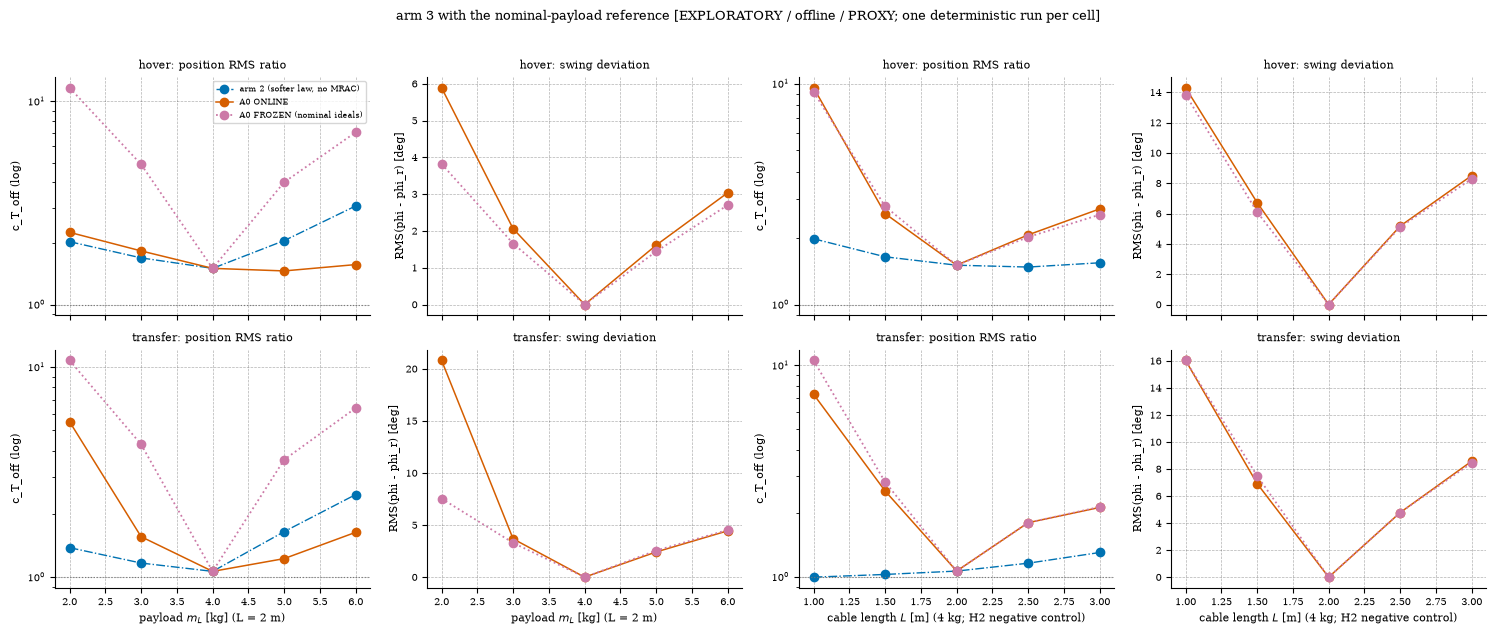

In [11]:
fig, ax = plt.subplots(2, 4, figsize=(15, 6.4), sharex="col")
SC = list(a0_grid.SCENARIOS)
mass_c = [(L_, m_) for (L_, m_, f) in a0_grid.CONDITIONS if f in ("mass", "nominal")]
len_c = [(L_, m_) for (L_, m_, f) in a0_grid.CONDITIONS if f in ("length", "nominal")]
len_c.sort()
def series(scn, conds, arm, col, x):
    out = []
    for (L_, m_) in conds:
        r = A0[(A0.scenario == scn) & (A0.L == L_) & (A0.m_L == m_) & (A0.arm == arm)].iloc[0]
        out.append((L_ if x == "L" else m_, r[col]))
    return np.array(out)
KEY = {"softer": "softer", "a0_online": "mrac", "a0_frozen": "frozen"}
style.LABEL_OVERRIDE.clear(); style.LABEL_OVERRIDE.update({"softer": "arm 2 (softer law, no MRAC)", "mrac": "A0 ONLINE", "frozen": "A0 FROZEN (nominal ideals)"})
for i, scn in enumerate(SC):
    for j, (conds, x, xl) in enumerate(((mass_c, "m", "payload $m_L$ [kg] (L = 2 m)"), (len_c, "L", "cable length $L$ [m] (4 kg; H2 negative control)"))):
        a_ = ax[i, 2 * j]
        for arm in a0_grid.COMPARED:
            s_ = series(scn, conds, arm, "c_T_off", x)
            a_.plot(s_[:, 0], s_[:, 1], marker="o", **style.arm_style(KEY[arm]))
        a_.axhline(1.0, color="#777777", lw=0.8, ls=":"); a_.set_yscale("log"); a_.set_ylabel("c_T_off (log)"); a_.set_title("%s: position RMS ratio" % SC[i], fontsize=8)
        b_ = ax[i, 2 * j + 1]
        for arm in ("a0_online", "a0_frozen"):
            s_ = series(scn, conds, arm, "dphi_rms_deg", x)
            b_.plot(s_[:, 0], s_[:, 1], marker="o", **style.arm_style(KEY[arm]))
        b_.set_ylabel("RMS(phi - phi_r) [deg]"); b_.set_title("%s: swing deviation" % SC[i], fontsize=8)
        if i == 1: a_.set_xlabel(xl, fontsize=8); b_.set_xlabel(xl, fontsize=8)
for a_ in ax.ravel(): a_.grid(True, alpha=0.3)
ax[0, 0].legend(fontsize=6)
fig.suptitle("arm 3 with the nominal-payload reference [EXPLORATORY / offline / PROXY; one deterministic run per cell]", fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.96)); plt.show()
style.LABEL_OVERRIDE.clear()

### 10.6 Interactive explorers
**Trajectories.** One condition and scenario; the true-mass PID+FF (denominator), arm 2, A0 ONLINE and A0 FROZEN on the standard six panels. Taut exits (none in the cached grid) would be noted under the figure.

In [12]:
CONDS = {COND_LABEL[(L_, m_)]: (m_, L_) for (L_, m_, f) in a0_grid.CONDITIONS}

def draw_a0_compare(cond, scenario, ff_true=True, arm2=True, online=True, frozen=True):
    m_, L_ = CONDS[cond]
    runs, notes = {}, []
    if ff_true: runs["ff_true"] = pid_record(base_run(m_, L_, scenario, "ff_true"))
    if arm2: runs["softer"] = pid_record(base_run(m_, L_, scenario, "softer"))
    for key, on, onl in (("mrac", online, True), ("frozen", frozen, False)):
        if on:
            a = a0_run(m_, L_, scenario, onl)
            if a["exit"] is not None: notes.append("%s: taut exit at t = %.2f s" % (key, a["exit"].tick * 0.02))
            if a["n"]: runs[key] = a
    style.LABEL_OVERRIDE.clear(); style.LABEL_OVERRIDE.update({"ff_true": "true-mass PID+FF (denominator)", "softer": "arm 2 (softer law, mass-blind FF, no MRAC)", "mrac": "arm 3 A0 ONLINE", "frozen": "arm 3 A0 FROZEN (nominal ideals)"})
    first = next(iter(runs.values()))
    fig = plots.standard_figure(runs, T_nom=m_ * G, ref=first if "ref_p" in first else None, title="A0 comparison, %s, %s" % (cond, scenario))
    if notes: fig.text(0.5, 0.005, "; ".join(notes), ha="center", color=style.SLACK_COLOR, fontsize=8)
    style.LABEL_OVERRIDE.clear()
    return fig

panel_a0_cmp = widgets.param_panel({
    "cond": ("dropdown", list(CONDS), COND_LABEL[(2.0, 6.0)], "condition"),
    "scenario": ("dropdown", list(a0_grid.SCENARIOS), "transfer", "scenario"),
    "ff_true": ("check", True, "true-mass PID+FF"),
    "arm2": ("check", True, "arm 2 (softer, no MRAC)"),
    "online": ("check", True, "A0 ONLINE"),
    "frozen": ("check", True, "A0 FROZEN"),
}, draw_a0_compare)

**Telemetry.** For one A0 episode: the six row estimates $[m_q,m_L,\mu_L]/\kappa$ and $[J,m_L,\mu_L]/\kappa_\tau$ (dashed: their **nominal ideals**, and the true $m_L$ in the force-row panel), $\hat\alpha$, **projection hits** (ticks at a box bound; the payload lower bound is 0), the swing of the plant, of the reference and their difference $\phi-\phi_r$ (**measured, not damped by the law**), the desired tilt increment $v$ and the filter error $\eta_0-v$. The estimates are controller coefficients, not identified physical parameters.

In [13]:
def draw_a0_telemetry(cond, scenario, mode):
    m_, L_ = CONDS[cond]
    a = a0_run(m_, L_, scenario, mode == "online"); t = a["t"]; nom = a["nominal_est"]
    fig, ax = plt.subplots(2, 3, figsize=(13.5, 6.4))
    names = [r"$\hat m_q/\kappa$", r"$\hat m_L$ (force row)", r"$\hat\mu_L$ (force row)", r"$\hat J/\kappa_\tau$", r"$\hat m_L$ (torque row)", r"$\hat\mu_L$ (torque row)"]
    cols = ["#000000", "#D55E00", "#0072B2", "#999999", "#E69F00", "#56B4E9"]
    for i in (0, 1, 2):
        ax[0, 0].plot(t, a["est"][:, i], color=cols[i], label=names[i]); ax[0, 0].axhline(nom[i], color=cols[i], lw=0.7, ls=":")
    ax[0, 0].axhline(m_, **style.arm_style("ref", label="true $m_L$")); ax[0, 0].set_title("force-row estimates [kg, kg, kg m]; dotted: nominal ideals", fontsize=8); ax[0, 0].legend(fontsize=6)
    for i in (3, 4, 5):
        ax[0, 1].plot(t, a["est"][:, i], color=cols[i], label=names[i]); ax[0, 1].axhline(nom[i], color=cols[i], lw=0.7, ls=":")
    ax[0, 1].set_title("torque-row estimates [kg m^2, kg, kg m]; dotted: nominal ideals", fontsize=8); ax[0, 1].legend(fontsize=6)
    ax[0, 2].plot(t, a["est"][:, 6], color="#CC79A7"); ax[0, 2].set_title(r"$\hat\alpha$ [m]", fontsize=8)
    for i in range(6):
        h = a["hits"][:, i]
        if h.any(): ax[1, 0].plot(t[h], np.full(h.sum(), i), "|", color=cols[i], ms=8)
    ax[1, 0].set_yticks(range(6), ["m_q", "m_L(p)", "mu(p)", "J", "m_L(th)", "mu(th)"], fontsize=7); ax[1, 0].set_ylim(-0.7, 5.7)
    ax[1, 0].set_title("projection hits (ticks at a box bound)", fontsize=8)
    ax[1, 1].plot(t, np.degrees(a["phi"]), color="#0072B2", label=r"$\phi$ (plant)"); ax[1, 1].plot(t, np.degrees(a["phi_r"]), color="#009E73", ls="--", label=r"$\phi_r$ (reference)")
    ax[1, 1].plot(t, np.degrees(a["dphi"]), color="#D55E00", label=r"$\phi-\phi_r$"); ax[1, 1].set_title("swing [deg]; the deviation is not damped by the law", fontsize=8); ax[1, 1].legend(fontsize=7)
    ax[1, 2].plot(t, a["v"], color="#009E73", label="v (desired tilt increment)"); ax[1, 2].plot(t, a["eta0_minus_v"], color="#CC79A7", label=r"$\eta_0-v$ (filter error)")
    ax[1, 2].set_title("tilt command and filter error [rad]", fontsize=8); ax[1, 2].legend(fontsize=7)
    for a_ in ax.ravel(): a_.set_xlabel("t [s]"); a_.grid(True, alpha=0.3)
    ex = a["exit"]
    fig.suptitle("A0 %s, %s, %s; %s [EXPLORATORY; estimates are controller coefficients]" % (mode, cond, scenario, "taut exit at %.2f s" % (ex.tick * 0.02) if ex else "no taut exit"), fontsize=9)
    fig.tight_layout(); return fig

panel_a0_tel = widgets.param_panel({
    "cond": ("dropdown", list(CONDS), COND_LABEL[(2.0, 6.0)], "condition"),
    "scenario": ("dropdown", list(a0_grid.SCENARIOS), "transfer", "scenario"),
    "mode": ("dropdown", ["online", "frozen"], "online", "variant"),
}, draw_a0_telemetry)

### 10.7 Observations (computed from the cache; each against the prediction of section 10.2)
The verdict column compares the number with the **direction written in section 10.2**; "supported" is not a test, only that the predicted direction occurred in this deterministic run. Note on A0-H2: section 10.2 says "16 cells per variant"; the correct count is **8 per variant** (4 masses x 2 scenarios), 16 over the two variants. The criterion (majority of cells with A0 better than arm 2) is unchanged.

In [14]:
D = A0
def cell(scn, L_, m_, arm, col):
    return float(D[(D.scenario == scn) & (D.L == L_) & (D.m_L == m_) & (D.arm == arm)][col].iloc[0])
SCN = list(a0_grid.SCENARIOS); MASSES = [2.0, 3.0, 5.0, 6.0]; LENS = [1.0, 1.5, 2.5, 3.0]
obs = []
def add(tag, text, value, verdict):
    obs.append(dict(id=tag, observation=text, value=value, verdict=verdict))

# A0-H1 nominal identity
dev = max(abs(cell(s, 2.0, 4.0, a, c) - cell(s, 2.0, 4.0, "softer", c)) for s in SCN for a in ("a0_online", "a0_frozen") for c in ("pos_rms_m", "swing_rms_deg"))
tele_nom = D[(D.L == 2.0) & (D.m_L == 4.0) & D.arm.isin(("a0_online", "a0_frozen"))]
add("A0-H1", "nominal cell: max |RMS(A0) - RMS(arm 2)| over both variants and scenarios; max est_dev; hit ticks; RMS(phi-phi_r)",
    "%.1e; %.1e; %d; %.1e" % (dev, tele_nom.est_dev_max.max(), int(tele_nom.hit_ticks.max()), tele_nom.dphi_rms_deg.max()),
    "supported" if dev < 1e-9 and tele_nom.est_dev_max.max() == 0.0 and tele_nom.hit_ticks.max() == 0 and tele_nom.dphi_rms_deg.max() == 0.0 else "refuted")

# A0-H2 mass mismatch: A0 position RMS below arm 2's
for arm in ("a0_online", "a0_frozen"):
    better = [(s, m_) for s in SCN for m_ in MASSES if cell(s, 2.0, m_, arm, "c_T_off_vs_arm2") < 1.0]
    heavy = sum(1 for (s, m_) in better if m_ > 4); light = sum(1 for (s, m_) in better if m_ < 4)
    n = len(better)
    add("A0-H2 " + arm, "cells (of 8) with A0 better than arm 2 in position RMS; of these heavier-than-nominal / lighter-than-nominal (4 + 4 cells)",
        "%d of 8 (heavier %d of 4, lighter %d of 4)" % (n, heavy, light), "supported" if n >= 5 else ("refuted" if n <= 3 else "inconclusive"))

# A0-H3 ONLINE vs FROZEN
ratios = [cell(s, 2.0, m_, "a0_online", "pos_rms_m") / cell(s, 2.0, m_, "a0_frozen", "pos_rms_m") for s in SCN for m_ in MASSES]
within = sum(abs(r_ - 1.0) < 0.10 for r_ in ratios)
add("A0-H3", "mass cells (of 8) with ONLINE within 10 % of FROZEN in position RMS; ONLINE/FROZEN range; ONLINE better in",
    "%d of 8; %.2f to %.2f; %d of 8" % (within, min(ratios), max(ratios), sum(r_ < 1 for r_ in ratios)),
    "supported" if within / 8 >= 0.8 else "refuted")

# A0-H4 swing deviation grows with |m_L - 4|; ONLINE vs FROZEN within 1.5
mono_ok = []
for s in SCN:
    for arm in ("a0_online", "a0_frozen"):
        v = [cell(s, 2.0, m_, arm, "dphi_rms_deg") for m_ in (2.0, 3.0, 4.0, 5.0, 6.0)]
        mono_ok.append(v[0] > v[1] > v[2] and v[2] < v[3] < v[4])
fac = [cell(s, 2.0, m_, "a0_online", "dphi_rms_deg") / cell(s, 2.0, m_, "a0_frozen", "dphi_rms_deg") for s in SCN for m_ in MASSES]
within15 = sum(1 / 1.5 <= f_ <= 1.5 for f_ in fac)
add("A0-H4", "(scenario, variant) series (of 4) with RMS(phi-phi_r) falling to 0 at 4 kg and rising again; mass cells (of 8) with ONLINE/FROZEN of that RMS within a factor 1.5",
    "%d of 4; %d of 8 (range %.2f to %.2f)" % (sum(mono_ok), within15, min(fac), max(fac)), "supported" if all(mono_ok) and within15 >= 5 else "mixed or refuted")

# A0-H5 length mismatch as negative control
bigger = 0; total = 0
for s in SCN:
    for arm in ("a0_online", "a0_frozen"):
        for L_ in LENS:
            for m_ in (3.0, 5.0):
                total += 1; bigger += cell(s, L_, 4.0, arm, "dphi_rms_deg") > cell(s, 2.0, m_, arm, "dphi_rms_deg")
add("A0-H5 (swing)", "comparisons (of 32: scenario x variant x length x {3, 5} kg) with RMS(phi-phi_r) at L != 2 above the 3 or 5 kg value", "%d of %d" % (bigger, total), "supported" if bigger == total else "mixed or refuted")
for arm in ("a0_online", "a0_frozen"):
    holds = []
    for s in SCN:
        ml = np.median([cell(s, L_, 4.0, arm, "c_T_off_vs_arm2") for L_ in LENS]); mm = np.median([cell(s, 2.0, m_, arm, "c_T_off_vs_arm2") for m_ in MASSES])
        holds.append((ml >= mm, ml, mm))
    add("A0-H5 (advantage) " + arm, "median position-RMS ratio to arm 2 over the 4 length cells >= over the 4 mass cells, per scenario (hover, transfer)",
        "; ".join("%s: %.2f vs %.2f" % (s, h[1], h[2]) for s, h in zip(SCN, holds)), "supported" if all(h[0] for h in holds) else "not supported for this variant")

# A0-H6 direction of the ONLINE force-row estimate in the transfer scenario
dirs = {m_: cell("transfer", 2.0, m_, "a0_online", "mLhat_p_end") for m_ in MASSES}
ok6 = all((dirs[m_] > 4.0) == (m_ > 4.0) for m_ in MASSES)
add("A0-H6", "transfer, ONLINE: force-row m_L-hat at the end of the run (kg)", "; ".join("%g kg: %.2f" % (m_, v_) for m_, v_ in dirs.items()), "supported" if ok6 else "refuted")

# A0-H7 taut domain
fails = D[D.failed]
add("A0-H7", "failed (taut-exit) episodes of %d" % len(D), int(len(fails)), "supported" if len(fails) == 0 else "refuted")
pinned = D[(D.hit_ticks > 0)][["scenario", "L", "m_L", "arm", "hit_ticks"]]
add("(not predicted)", "cells with at least one tick at an estimate box bound (scenario, L, m_L, variant, ticks)", "; ".join("%s L=%g m=%g %s: %d" % tuple(r_) for r_ in pinned.itertuples(index=False)) or "none", "")
add("(not predicted)", "true-mass PID+FF is better than all three compared controllers in position RMS (all three c_T_off above 1) in how many of the 16 non-nominal cells?",
    "%d of 16" % sum(all(cell(s, L_, m_, a, "c_T_off") > 1 for a in a0_grid.COMPARED) for s in SCN for (L_, m_, f) in a0_grid.CONDITIONS if f != "nominal"), "")
display(pd.DataFrame(obs).style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

id,observation,value,verdict
A0-H1,nominal cell: max |RMS(A0) - RMS(arm 2)| over both variants and scenarios; max est_dev; hit ticks; RMS(phi-phi_r),0.0e+00; 0.0e+00; 0; 0.0e+00,supported
A0-H2 a0_online,cells (of 8) with A0 better than arm 2 in position RMS; of these heavier-than-nominal / lighter-than-nominal (4 + 4 cells),"4 of 8 (heavier 4 of 4, lighter 0 of 4)",inconclusive
A0-H2 a0_frozen,cells (of 8) with A0 better than arm 2 in position RMS; of these heavier-than-nominal / lighter-than-nominal (4 + 4 cells),"0 of 8 (heavier 0 of 4, lighter 0 of 4)",refuted
A0-H3,mass cells (of 8) with ONLINE within 10 % of FROZEN in position RMS; ONLINE/FROZEN range; ONLINE better in,0 of 8; 0.19 to 0.51; 8 of 8,refuted
A0-H4,"(scenario, variant) series (of 4) with RMS(phi-phi_r) falling to 0 at 4 kg and rising again; mass cells (of 8) with ONLINE/FROZEN of that RMS within a factor 1.5",4 of 4; 6 of 8 (range 0.95 to 2.76),supported
A0-H5 (swing),"comparisons (of 32: scenario x variant x length x {3, 5} kg) with RMS(phi-phi_r) at L != 2 above the 3 or 5 kg value",32 of 32,supported
A0-H5 (advantage) a0_online,"median position-RMS ratio to arm 2 over the 4 length cells >= over the 4 mass cells, per scenario (hover, transfer)",hover: 1.66 vs 0.90; transfer: 2.06 vs 1.04,supported
A0-H5 (advantage) a0_frozen,"median position-RMS ratio to arm 2 over the 4 length cells >= over the 4 mass cells, per scenario (hover, transfer)",hover: 1.67 vs 2.59; transfer: 2.19 vs 3.13,not supported for this variant
A0-H6,"transfer, ONLINE: force-row m_L-hat at the end of the run (kg)",2 kg: 0.00; 3 kg: 1.07; 5 kg: 4.05; 6 kg: 5.98,supported
A0-H7,failed (taut-exit) episodes of 72,0,supported


**Two follow-up computations** (not predicted in section 10.2, so they are labelled as such): (i) the steady height offset of A0 FROZEN against the hand estimate $(m_L-4)\,g/(k_p\lambda_p)$ that a fixed estimate with a soft gain would leave (the law has **no integrator on the plant error**; arm 2 has the PID integrator); (ii) the swing RMS $\phi-\phi_{eq}$ of A0 against arm 2.

In [15]:
rows = []
for m_ in MASSES:
    a = a0_run(m_, 2.0, "transfer", False); o = a0_run(m_, 2.0, "transfer", True)
    last = slice(-100, None)                                   # last 2 s of the 8 s transfer episode (reference held)
    ez_f = float(np.mean(a["p"][last, 1] - a["ref_p"][last, 1])); ez_o = float(np.mean(o["p"][last, 1] - o["ref_p"][last, 1]))
    hand = -(m_ - 4.0) * G / (LAW["k_p"] * LAW["lambda_p"])
    rows.append(dict(m_L=m_, hand_estimate_m=hand, FROZEN_mean_z_error_m=ez_f, ONLINE_mean_z_error_m=ez_o))
display(Markdown("**(i) transfer scenario, last 2 s: mean $z$ error of the vehicle [m]** against the hand estimate $-(m_L-4)g/(k_p\\lambda_p)$ (a hand estimate, not a derivation)"))
display(pd.DataFrame(rows).style.format({c: "{:.3f}" for c in ("hand_estimate_m", "FROZEN_mean_z_error_m", "ONLINE_mean_z_error_m")}).hide(axis="index"))
n_worse = sum(cell(s, 2.0, m_, "a0_online", "swing_rms_deg") > cell(s, 2.0, m_, "softer", "swing_rms_deg") for s in SCN for m_ in MASSES)
n_worse_f = sum(cell(s, 2.0, m_, "a0_frozen", "swing_rms_deg") > cell(s, 2.0, m_, "softer", "swing_rms_deg") for s in SCN for m_ in MASSES)
n_len = sum(cell(s, L_, 4.0, "a0_online", "c_T_off_vs_arm2") > 1.0 for s in SCN for L_ in LENS)
n_len_f = sum(cell(s, L_, 4.0, "a0_frozen", "c_T_off_vs_arm2") > 1.0 for s in SCN for L_ in LENS)
display(Markdown("**(ii)** swing RMS $\\phi-\\phi_{eq}$ above arm 2's in %d of 8 mass cells (ONLINE) and %d of 8 (FROZEN). **(iii)** position RMS above arm 2's in %d of 8 length cells (ONLINE) and %d of 8 (FROZEN)." % (n_worse, n_worse_f, n_len, n_len_f)))

**(i) transfer scenario, last 2 s: mean $z$ error of the vehicle [m]** against the hand estimate $-(m_L-4)g/(k_p\lambda_p)$ (a hand estimate, not a derivation)

m_L,hand_estimate_m,FROZEN_mean_z_error_m,ONLINE_mean_z_error_m
2.000000,0.654,0.623,0.005
3.000000,0.327,0.318,0.004
5.000000,-0.327,-0.325,0.004
6.000000,-0.654,-0.656,0.001


**(ii)** swing RMS $\phi-\phi_{eq}$ above arm 2's in 8 of 8 mass cells (ONLINE) and 7 of 8 (FROZEN). **(iii)** position RMS above arm 2's in 8 of 8 length cells (ONLINE) and 8 of 8 (FROZEN).

### 10.8 Interpretation (EXPLORATORY, offline, PROXY)
**Historical short-horizon interpretation only. Section 11 supersedes any inference of long-horizon stability. Existing outputs are retained, not regenerated.**
Mechanisms below are **INFERRED** from the numbers above; none was isolated by an ablation, and every statement is for one deterministic run per cell of this reduced model.

* **Identity (A0-H1).** At the nominal load the plant equals the reference and the A0 episodes reproduce arm 2 exactly (difference 0.0, no estimate movement, no projection hit, $\phi-\phi_r\equiv0$). This is the notebook-level echo of the bit-for-bit unit test, and it shows the reference was assembled consistently with arm 2 (same PID+FF, same softer law).
* **FROZEN is not a useful comparator for a payload mismatch (A0-H2, A0-H3).** With the estimates held at the nominal ideals the law has no integrator on the plant error, so a payload-weight mismatch leaves a steady offset. The table of section 10.7 compares it with the hand estimate $(m_L-4)g/(k_p\lambda_p)$: agreement within 5 % (computed above: FROZEN mean offsets 0.62, 0.32, -0.33, -0.66 m for 2, 3, 5, 6 kg against 0.65, 0.33, -0.33, -0.65 m; a hand estimate, not a derivation), while ONLINE removes the offset (at most 5 mm), consistent with the adapting payload coefficient acting as an integrator (INFERRED). FROZEN is therefore worse than arm 2, which has the PID integrator, in all 8 mass cells. A0-H3 is **refuted in the strong direction**: ONLINE is 2 to 5 times lower than FROZEN in position RMS in all 8 mass cells, not within 10 %.
* **ONLINE against arm 2 is mixed (A0-H2).** ONLINE has a lower position RMS than arm 2 at the **heavier** loads (5 and 6 kg, both scenarios, 4 of 4 cells) and a higher one at the **lighter** loads (2 and 3 kg, 0 of 4 cells better). At 2 kg in the transfer the force-row $\hat m_L$ is **pinned at its lower bound 0** for 110 of 400 ticks and $\phi-\phi_r$ reaches 52 degrees at its peak: the worst cell of the grid. The cause of the asymmetry is **not diagnosed** (candidates: the lower box bound at 0, the swing driving the coefficient as in the preliminary run, the soft gains); the excitation diagnostics of MQP 6.9 were not computed. The true-mass PID+FF, an almost perfect tracker, is better than all three compared controllers in 15 of the 16 non-nominal cells. **No benefit over arm 2 is shown.**
* **Swing deviation (A0-H4).** RMS of $\phi-\phi_r$ falls to 0 at 4 kg and grows on both sides in both scenarios and both variants, as predicted for a law that adds no damping to it; ONLINE and FROZEN agree within a factor 1.5 in 6 of 8 cells (the 2 kg cells are the exceptions, where ONLINE is pinned at the lower bound). The swing RMS $\phi-\phi_{eq}$ of A0 is **higher** than arm 2's in 8 of 8 mass cells for ONLINE and 7 of 8 for FROZEN (computed above): the damping of the reference model is not inherited by the plant here.
* **Length mismatch, the negative control (A0-H5).** The swing deviation is larger at every $L\ne2$ than at 3 and 5 kg (32 of 32 comparisons), as expected when the reference carries $l_r=2$ m; A0 is **worse than arm 2** in position RMS in every length cell for ONLINE and (computed above) FROZEN. For ONLINE the relative disadvantage is larger at length mismatch than at mass mismatch; for FROZEN the median ratio is larger at mass mismatch (FROZEN's mass-mismatch offset is itself large), so the A0-H5 second clause is **not supported for FROZEN**. At $L=1$ m the ONLINE force-row estimate is pinned at 0 for 16 (hover) and 22 (transfer) ticks.
* **Estimate directions (A0-H6).** The ONLINE force-row $\hat m_L$ ends on the side of 4 kg that matches the mismatch for all four masses (0.00, 1.07, 4.05, 5.98 kg for 2, 3, 5, 6 kg), but the 2 kg estimate is the box floor, not an estimate of 2 kg. These are controller coefficients; they are **not** identified masses and no convergence is claimed. The torque-row $\hat m_L$ stays within 0.02 kg of 4 kg in every ONLINE cell (3.988 to 4.001 kg).
* **Taut domain (A0-H7).** No taut exit in any of the 72 episodes, including the hover release at $L=1$ m.
* **What this does not show.** No stability, convergence or benefit claim; no claim about the Pymunk chain plant; the length mismatch is outside the matched-uncertainty argument (MQP 6.13 item 6) and the results are consistent with that, not a test of it. The law gains were chosen for the preliminary run and not retuned for the nominal-payload reference; a different tuning could change every ratio. Which of ONLINE, FROZEN and arm 2 is better is a question for a pre-registered protocol (W5), not for this notebook.

### 10.9 Limits, NOT RUN and next steps
* **One deterministic run per cell, two scenarios, nine conditions, one set of law gains** (those of the PRELIMINARY run, fixed once by a short-horizon scan at 4 kg, not a stability assessment, and **not retuned** for the reference of section 10), one reference trajectory per scenario. No seeds, no confidence intervals: the table gives directions only.
* **Reference initialisation** `copy_kinematics` (decision Q1): in the hover scenario the reference copies the released cable angle $\phi_0=0.35$ rad, so it damps the same initial swing; the plant under mismatch does not follow it exactly.
* **FROZEN** is held at the nominal ideals (decision Q2). The legacy "payload 0" variant and FROZEN-learned are **not run** here.
* **No stability, convergence or benefit claim.** The estimates are controller coefficients; the mechanism of any ONLINE-versus-FROZEN difference is **INFERRED**, not isolated (no excitation diagnostics $G_p$, $G_\theta$ of MQP 6.9, no ablation of the swing term).
* **Historical NOT RUN list:** Pymunk episodes, training, wind or kick forcing, vehicle-parameter mismatch together with payload mismatch, the oracle form of the swing law, other reference trajectories or gains. Section 11 adds the approved long-horizon diagnostic and a PROPOSED local sampled-data Jacobian. Independent acceptance of these new findings is pending.

## 11. Long-horizon failures, matching and robustness

**VERIFIED:** the approved fixed-gain 6 kg / 2 m transfer-and-hold diagnostic reproduces failure of both loaded-reference and no-load-reference MRAC. The direct softer law completes the requested horizon. The saved table below keeps every failed arm. These are reduced-model development-PC PROXY observations, not a population comparison or stability certificate. No gain tuning or disturbance-estimator run was performed.

This notebook's preliminary `_arrays` adapter previously paired post-step body states with pre-step task samples, and used within-step taut-exit time as absolute episode time. It now uses pre-step body/reference samples and tick*T_s+stage_time for absolute failure time. Coefficient history `est` remains post-update at t+T_s. Existing outputs and cached CSVs are historical and were **not rescored or overwritten**. Executed notebook backups were preserved before edits. The legacy interactive sections still launch short episodes; do not execute the entire notebook without approval. Section 10 now reads the existing cache without automatic regeneration or three extra reproducibility episodes.

| Obligation | Result for this recipe |
|---|---|
| Timing | T_s=T_adapt=0.02 s, sim_dt=0.002 s |
| Ideal force / torque coefficients | [9.6,6,12] / [1.5447816,6,12], alpha=0, inside all projection boxes |
| Adaptive gains | Gamma_p=(0.05,3,3), Gamma_theta=(0.01,0.01,0.01), gamma_alpha=0.0001, unchanged |
| Feedback / filter | lambda_p=1.5, lambda_theta=5, k_p=20, k_theta=25; Hurwitz (s+5)^3 |
| Q algebra | Placeholder-family worst margin 6.78724, not a stability margin |
| Actual thrust-domain premise | Violated by every MRAC arm; clipping does not repair the requested-input premise |
| Full matching | Generalized regressor exactness does not eliminate the rank-two input / attitude cascade / swing / motor-lag residuals |
| Robustness | No sampled-data certificate, residual envelope, sigma/e modification or dead zone |
| Disturbance model | D_v=0; no unknown-weight basis estimator is implemented |
| Identification | No PE or physical-parameter convergence claim; independent row coefficients |

Both FROZEN and ONLINE fail. The nominal references remain close to the task when the real plants stop. Therefore neither adapting gains alone nor reference instability explains all failures. A0 FROZEN exceeds 0.2 rad filter error at 7.44 s, before saturation at 16.82 s and requested-thrust domain violation at 16.86 s. This ordering is not a causal ablation.

The PROPOSED EQ-MR-16 hover Jacobian retains the lateral/swing/attitude loop, first-order motor lag, exact ZOH filter, old-filter command order and the -M_dot s/2 terms. Its saved eigenvalue moduli exceed one even with ideal payload coefficients. This is a symbolically checked, derived-under-assumptions local mechanism, not accepted nonlinear proof. Generic nonideal ONLINE states are not equilibrium points and were not linearized. See [NB09, sections 8.1-8.3](09_MRAC_Nominal_Load_Reference.ipynb) for the equations, uncertainty-weight cancellation candidate, units and matching conditions. The candidate estimator is **NOT IMPLEMENTED** and is not an established cure for the unstable cascade. Arbitrary world-lateral force is not instantly matched to collective thrust.

NB02's scalar matched model, NB03's matrix model and NB04's SISO theorem must not be transferred without checking their conditions. NB03's dimension/storage exposition and NB04's generic negative-companion-row Hurwitz statement need care. The actual gain/filter checks above use the implemented equations, not those shortcuts. Independent scientific/software acceptance remains pending. The MRAC law is diagnosed, **not fixed or tuned**.

In [16]:
import json
DIAG_DIR = Path('results/mrac_long_horizon_20261124T231900')
diagnostic_receipt = json.loads((DIAG_DIR / 'receipt.json').read_text(encoding='utf-8'))
if diagnostic_receipt['status'] != 'completed':
    raise RuntimeError('Incomplete diagnostic receipt; inspect preserved evidence before scoring')
display(pd.DataFrame([
    dict(arm=arm, completed_ticks=s['n_completed'], requested_ticks=s['n_requested'],
         stop_time_s=s['stop_time_s'], stop=s['stop']['kind'] if s['stop'] else 'completed',
         max_requested_thrust_N=s['requested_thrust_max_N'],
         Q_domain_violating_ticks=s['q_domain_violating_ticks'])
    for arm, s in diagnostic_receipt['summaries'].items()
]))
hover_audit = json.loads((DIAG_DIR / 'hover_linearization.json').read_text(encoding='utf-8'))
display(pd.DataFrame([dict(case=k, spectral_radius=v['spectral_radius'],
                          growth_rate_per_s=v['growth_rate_per_s'])
                      for k, v in hover_audit['cases'].items()]))
print('Saved evidence only. No additional episodes, estimator or gain tuning.')


,arm,completed_ticks,requested_ticks,stop_time_s,stop,max_requested_thrust_N,Q_domain_violating_ticks
0,direct_softer,6000,6000,120.000,completed,163.144441,0
1,a0_frozen,1204,6000,24.080,task_error_10m,537.887107,138
2,a0_online,905,6000,18.100,task_error_10m,1978.217186,142
3,no_load_frozen,326,6000,6.532,taut_exit,222.971205,24
4,no_load_online,297,6000,5.947,taut_exit,440.306823,103


,case,spectral_radius,growth_rate_per_s
0,a0_nominal_frozen,1.003002,0.149862
1,a0_ideal_frozen,1.004525,0.225750
2,a0_ideal_online_alpha,1.004377,0.218377
3,no_load_nominal_frozen,1.008352,0.415848
4,no_load_ideal_frozen,1.006723,0.335017


Saved evidence only. No additional episodes, estimator or gain tuning.


## 12. Root cause and structural modification (EQ-MR-18, PROPOSED)

The failures in section 11 have three mechanisms; the full derivation and the review corrections are in [NB09 section 9](09_MRAC_Nominal_Load_Reference.ipynb).
- **C1:** the outer lateral PD loop through the `(s+5)^3` tilt filter has a continuous phase margin of about -11 deg. This holds with ideal attitude, no motor lag and no payload, for `F(s)((m_hat_q lambda_p + k_p) s + k_p lambda_p)/(m s^2)`.
- **C2:** the payload regressor cancels the **measured** cable pull, which leaves the real swing deviation as near-marginal zero dynamics.
- **C3:** a vertical lumped-mass adaptive mode that grows slightly in the sampled model, at +0.005 / s with a 1.38 s period at 6 kg.

The opt-in modification has two parts, and no adaptation or feedback gain changes:
- `swing_regressor="reference"`: the regressor, in the command and in the adaptation update, uses the reference swing (here, the quasi-static `atan2(-p_ddot_r,y, g + p_ddot_r,z)`);
- tilt filter `(s+20)^3`: the smallest pole in {5, 7.5, 10, 15, 20} rad/s whose ideal-loop phase margin is at least 45 deg. It gives 46 deg, or about 34 deg with motor lag and a half-sample delay.

Effect:
- It removes the local hover instabilities attributed to C1 and C2: 0 of the 18 distinct hover linearizations grow.
- The approved 120 s episodes of the no-load-reference arms (this notebook's design) now complete. The ONLINE one has 19 saturation ticks, so completion does not mean acceptable.
- **C3 is not fixed.** FROZEN keeps the expected 1.962 m altitude offset `6 g/(k_p lambda_p)`, because the law has no integral or bias action. In ONLINE, `m_L,hat` reaches the projection bound of 10 kg from 0.54 s.

PROXY, EXPLORATORY. Reviewed: CONDITIONAL after corrections. The cell reads saved results only.

In [17]:
import json
for name in ('mrac_stabilized_core_20261124T230930',):
    rec = json.loads((Path('results') / name / 'receipt.json').read_text(encoding='utf-8'))
    display(pd.DataFrame([dict(arm=a, stop=s['stop']['kind'] if s['stop'] else 'completed',
                               stop_time_s=s['stop_time_s'], task_rms_90_120s_m=s['task_rms_90_120s_m'],
                               swing_rms_90_120s_rad=s['swing_rms_90_120s_rad'])
                          for a, s in rec['summaries'].items() if a.startswith('no_load')]))
print('Saved evidence only. Stabilized variant EQ-MR-18 (PROPOSED).')

,arm,stop,stop_time_s,task_rms_90_120s_m,swing_rms_90_120s_rad
0,no_load_frozen,completed,120.0,1.962000,4.090560e-09
1,no_load_online,completed,120.0,0.094229,2.307750e-08


Saved evidence only. Stabilized variant EQ-MR-18 (PROPOSED).


## 13. σ-modification, input-bias ablation and OU wind (no-load reference)

The setup and the predictions are as in [NB09 §10](09_MRAC_Nominal_Load_Reference.ipynb): scope A, approved 2026-11-25, 6 kg / 2 m, OU wind μ = (5, −3, 0.5), seeds 1 to 3; σ and Γ_d set by the stated rules (EQ-MR-19/20), no other gain changed.

Arm `no_load_online`; the no-wind column is 1 episode, the OU columns are the mean of 3 seeds, and saturation is the max.

| Variant | Task RMS 90-120 s (m), no wind | Task RMS 90-120 s (m), OU | Mean e_y 90-120 (m), OU | Mean e_z 90-120 (m), OU | M̂ rate, no wind (/s) | Saturation / Q-violating ticks (max), OU |
|---|---|---|---|---|---|---|
| stabilized | 0.094 | 0.092 | +0.085 | +0.001 | +0.001 | 27 / 17 |
| +σ | 0.065 | 0.114 | +0.088 | −0.068 | −0.212 | 21 / 16 |
| +bias | 0.017 | 0.023 | −0.001 | +0.000 | −0.025 (M̂ std 0.52 kg) | 149 / 54 |
| +σ+bias | 0.062 | 0.077 | +0.037 | −0.065 | −0.166 | 35 / 19 |

- The `bound` column counts 6000 ticks because μ_p and μ_θ sit at their lower bound 0 throughout (the no-load reference has no swing to excite them). m̂_L,p touches its 10 kg bound only briefly (126 ticks stabilized, 13 ticks +σ; final 4.59 and 5.71 kg). Completion here still does not mean acceptable adaptation.
- σ = 0.5: no-wind task RMS 0.065 m vs 0.065 m predicted; −0.068 m mean e_z under OU wind, including the −3 N mean.
- `+bias` gives the best mean tracking, at the cost of about 4 to 7 times more saturation ticks per seed (max 149 vs 27).
- The frozen σ arm (no wind) keeps the expected 1.962 m offset: nothing adapts and nothing leaks in frozen arms.

EXPLORATORY, PROXY; no stability claim; no variant is selected.

In [18]:
import json
from pathlib import Path
import pandas as pd

rows = json.loads(Path("results/mrac_scopeA_sigma_bias_wind_20261125/scopeA_summary.json").read_text())
df = pd.DataFrame(rows)
df = df[df["arm"].str.startswith("no_load_")]
cols = ["variant", "wind", "arm", "status", "task_rms_90_120", "mean_ey_90_120", "mean_ez_90_120",
        "swing_rms_90_120", "sat", "qviol", "bound", "fmax", "M_std_90_120", "M_rate", "M_final", "d_final"]
df[cols].sort_values(["wind", "variant", "arm"]).round(4)

,variant,wind,arm,status,task_rms_90_120,mean_ey_90_120,mean_ez_90_120,swing_rms_90_120,sat,qviol,bound,fmax,M_std_90_120,M_rate,M_final,d_final
9,stabilized,none,no_load_online,completed,0.0942,NaN,NaN,0.0000,19,13,6000,219.3281,2.9268,0.0005,14.3722,"[0.0, 0.0, 0.0]"
1,stabilized_bias,none,no_load_online,completed,0.0167,NaN,NaN,0.0000,126,71,6000,222.3701,0.5216,-0.0250,17.4242,"[0.000029, 14.338466, -0.096181]"
26,stabilized_sigma,none,no_load_frozen,completed,1.9620,NaN,NaN,0.0000,0,0,6000,166.8947,0.0000,NaN,9.6000,"[0.0, 0.0, 0.0]"
27,stabilized_sigma,none,no_load_online,completed,0.0646,NaN,NaN,0.0000,19,13,6000,215.8498,0.0000,-0.2115,15.4023,"[0.0, 0.0, 0.0]"
17,stabilized_sigma_bias,none,no_load_online,completed,0.0620,NaN,NaN,0.0000,20,15,6000,217.7730,0.0000,-0.1659,15.1626,"[0.0, -2.432123, -0.0]"
13,stabilized,ou,no_load_online_wind1,completed,0.1027,0.0943,0.0006,0.0088,27,16,6000,223.8510,0.7007,-0.0088,16.0289,"[0.0, 0.0, 0.0]"
14,stabilized,ou,no_load_online_wind2,completed,0.0910,0.0862,0.0008,0.0113,22,16,6000,223.6755,0.7402,-0.0110,15.1049,"[0.0, 0.0, 0.0]"
15,stabilized,ou,no_load_online_wind3,completed,0.0829,0.0759,0.0006,0.0086,24,17,6000,224.0985,0.7113,-0.0080,15.6060,"[0.0, 0.0, 0.0]"
5,stabilized_bias,ou,no_load_online_wind1,completed,0.0239,0.0012,0.0002,0.0094,133,48,6000,226.9082,0.5164,-0.0238,17.4051,"[3.992743, 11.347674, -0.476912]"
6,stabilized_bias,ou,no_load_online_wind2,completed,0.0187,-0.0034,0.0002,0.0097,149,54,6000,226.7594,0.3944,-0.0291,16.9211,"[2.189928, 11.544435, -0.412831]"


## 14. Where this continues (2026-11-25)

- **NB09 §11:** why the A0 adaptation does not converge. After the transfer the $m_q$ and $m_L$ columns are collinear (rank-1 Gramian), only the lumped mass is informed, and it carries the growing C3 mode. σ freezes it with an offset.
- **NB10:** a second law, *vanilla state-space MRAC in Guha notation* (EQ-MR-22, MQP §6.14). The swing error is inside the error model and the linear damper is in $A_H$. It has an exact Lyapunov result ($\dot V=-e^\top Qe$, $e\to0$) on the linearized matched outer model, and the sampled loop is checked at hover before tuning. The A0 law here is unchanged and remains the comparator.